In [232]:
# population studies using multi-class classification
import numpy as np
import pandas as pd
from matplotlib import pyplot
import matplotlib.colors as mcolors
from scipy.stats import binom
print(np.__version__)
from scipy.optimize import minimize
from scipy.interpolate import interp1d
from astropy.io import fits

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.calibration import calibration_curve

import os
import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.26.4


In [233]:
if 1:
    import importlib
    importlib.reload(util);


In [234]:
erg2GeV = 1.6e3

In [235]:
def log_par_sp(Es, E0, indE0, beta, norm=1., same_dim=False):
    logE = np.log(Es/E0)
    if type(Es) == np.ndarray and not same_dim:
        if type(norm) != float:
            norm = np.outer(norm, np.ones_like(logE))
        return norm * np.exp(-np.outer(indE0, logE)  - np.outer(beta, logE**2))
    else:
        return norm * np.exp(-indE0 * logE  - beta * logE**2)

def BL2xyz(B, L):
    theta = np.pi / 2. - np.deg2rad(B)
    phi = np.deg2rad(L)
    x = np.sin(theta) * np.cos(phi)
    y = np.sin(theta) * np.sin(phi)
    z = np.cos(theta)
    return x, y, z

def mask_circle(Bs, Ls, R_max):
    cos_max = np.cos(np.deg2rad(R_max))
    xs = BL2xyz(Bs, Ls)[0]
    return xs > cos_max

def mask_rect(Bs, Ls, Bmin=-20, Bmax=20, Lmin=-20, Lmax=20):
    return (Bs > Bmin) & (Bs < Bmax) & (Ls > Lmin) & (Ls < Lmax)

def mask_quad_ring(Bs, Ls, R_max=20., R_min=0., qname='W'):
    cos_max = np.cos(np.deg2rad(R_max))
    cos_min = np.cos(np.deg2rad(R_min))
    xs, ys, zs = BL2xyz(Bs, Ls)
    mask = xs > cos_max
    mask &= xs < cos_min
    if qname == 'W':
        mask &= (ys < -np.abs(zs))
    elif qname == 'E':
        mask &= (ys > np.abs(zs))
    elif qname == 'S':
        mask &= (zs < -np.abs(ys))
    elif qname == 'N':
        mask &= (zs > np.abs(ys))
    return mask

def ring_area_sr(R_max=20., R_min=0., phi=360.):
    return np.deg2rad(phi) * (np.cos(np.deg2rad(R_min)) - np.cos(np.deg2rad(R_max)))

#def get_cl_ind(dec_tree_cat_dict, cl):
#    for ind, cls in dec_tree_cat_dict.items():
#        if cl in cls:
#            return ind
get_cl_ind = util.get_cl_ind

def get_ulim_mask(vs, errs, sigma=2):
    return vs < sigma * errs


# function to work with Fermi-LAT flags

def norm_flag(fl_str, len_max=14):
    res = fl_str[2:]
    res = '0'*(len_max - len(res)) + res
    return res

def flag2bin_str(flag):
    return norm_flag(bin(int(flag)))

flag2bin_str_vec = np.frompyfunc(flag2bin_str, 1, 1)

def get_flag_mask(flags, flag_list):
    flags_bin_str = flag2bin_str_vec(flags)
    mask = True
    for flag in flag_list:
        mask &= ~np.array([(st[-flag] == '1') for st in flags_bin_str])
    return mask

Es_plot = np.logspace(-1., 2., 31)
def get_LP_spectra(mask, Es_plot=Es_plot, Eind=2.):
    sps = log_par_sp(Es_plot, E0, indE0[mask], beta[mask], norm=LP_norm[mask], same_dim=False)
    return Es_plot**Eind * sps

def get_weights(cat_df, cl_inds, alg, mask):
    weights = 0.
    for cl_ind in cl_inds:
        weights += np.array(cat_df['%i_%s' % (cl_ind, alg)][mask])
    return weights


def strikethrough(mytext):
    ''' replacing space with 'non-break space' and striking through'''
    #return("\u0336".join(mytext.replace(" ","\u00a0"))+ "\u0336")
    return '!%s' % mytext
def right_arrow():
    return '\u2192'

Acc = 2.5e4 # cm^2 sr
fsaa = 0.8
Aeff = fsaa * Acc / (4. * np.pi) # cm^2
def exposure(nyear):
    T = nyear * 365 * 24 * 3600. # s
    return Aeff * T

def get_SdNdS(fn, kind=1, n0=2):
    data = np.loadtxt(fn, delimiter=',').T
    ff = interp1d(data[0], data[1], kind=kind, fill_value="extrapolate")
    def SdNdS(S):
        log10S = np.log10(S)
        log10F = (1 - n0) * log10S + ff(log10S) #+ np.log10(Area_c)
        return 10**(log10F)
    return SdNdS


In [236]:
script_fn = 'fermi_multiclass/notebooks/pop_studies/MSP_GC_flux.ipynb'
fig_meta = {'Authors': ['Dmitry Malyshev'], 'Subject': script_fn}

spatial_mask_type = 'R10' # 'R10', 'S40_G4', 'R10-20'

# select the catalog and the case
cat_name = '4FGL-DR4' # '4FGL-DR3'
if cat_name == '4FGL-DR4':
    #baseline_case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    #case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' 
    baseline_case = '4FGL-DR4_GMM_RF'
    #case = '4FGL-DR4_GMM_RF' 
    #case = '4FGL-DR4_GMM_RF_no_bcu_spp' 
    #case = '4FGL-DR4_GMM_RF_no_coord' 
    case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
elif cat_name == '4FGL-DR3':
    baseline_case = '4FGL-DR3_GMM_RF'
    case = '4FGL-DR3_GMM_RF' 

baseline = (case == baseline_case)
root_folder = '../../'
config_folder = root_folder + 'config/'

# generic inputs
cdict = util.get_config_dict(baseline_case=baseline_case, 
                             case=case, 
                             folder=config_folder)

cdict['root_folder'] = root_folder
folder_in = cdict['root_folder'] + cdict.get('folder_in', 'data_in/')
folder_out = cdict.get('folder_out', root_folder + 'data_out/')
folder = folder_out
Eind = int(cdict.get('Eind', 1000))
class_name = cdict.get('class_name', 'CLASS1')

cat_folder = '%s/results/%s_probabilistic_catalogs/' % (cdict['root_folder'], util.get_cat_descr(cdict))
cat_fn = cat_folder + util.get_cat_descr(cdict) + '_prob_cat.csv'
cat_df = pd.read_csv(cat_fn, index_col=0)

assoc_sources = cdict.get('assoc_sources', 'all_assoc')
sep_model = cdict.get('sep_model', 'GMM')
tree_alg = sep_model
#sep_model = 'RF' # 'GMM', 'RF'
nmin = cdict.get('nmin')
if nmin is not None: 
    nmin = int(nmin)
max_depth = int(cdict.get('max_depth', 5))
feature_mode = cdict.get('features', 'all_features')


tree_cat_fn = util.get_tree_cat_fn(cdict)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
if util.exist_internal(tree_cat_dict):
    util.remove_internal(tree_cat_dict)
max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
nodes = [str(key) for key in dec_tree_cat_dict.keys()]

        

all_assoc = []
for cls in tree_cat_dict.values():
    all_assoc.extend(cls)

xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)
ns = len(xdf)

all_features = [name for name in xdf.columns if name.find('CLASS') == -1]
if feature_mode == 'all_features':
    features = all_features
elif feature_mode == 'no_coord_features':
    features = [feat for feat in all_features if feat.find('GL') == -1]


nsrc_dict = util.get_nsrc_dict(xdf, class_column=class_name, classes='associated')
nsrc_df = util.nsrc_dict2df(nsrc_dict)

if 0:
    # algorithm description string
    pars_dict = util.pars_dict
    pars_dict['NN']['nfeatures'] = len(features)
    pars_dict['NN']['epochs'] = cdict.get('epochs', 500)
    #alg_descr = util.get_alg_descr(cdict, pars_dict=pars_dict)

    
cls_mp = ['msp', 'psr']
cl_str_mp = 'msp,psr+'
cl_inds_mp = [get_cl_ind(dec_tree_cat_dict, cl) for cl in cls_mp]
cl_list_mp = []
for cl_ind in cl_inds_mp:
    cl_list_mp.extend(dec_tree_cat_dict[cl_ind])
    print(cl_inds_mp, dec_tree_cat_dict[cl_ind])

add_msp_psr = 0
if not add_msp_psr:
    cl = 'msp' # 'msp', 'psr'
    cls = [cl]
    cl_str = '%s+' % cl
    cl_ind = get_cl_ind(dec_tree_cat_dict, cl)
    cl_inds = [cl_ind]
    cl_list = dec_tree_cat_dict[cl_ind]
    print(cl_ind, dec_tree_cat_dict[cl_ind])
else:
    cl_list = cl_list_mp
    cl_inds = cl_inds_mp

unas_type = 'unas' # 'unas', 'unk', bcu', 'spp', 'all_not_assoc'
descr_str_folder = util.get_cat_descr(cdict)
descr_str = '%s_%s' % (descr_str_folder, unas_type)
for cl in cls:
    descr_str += '_%s' % (cl)
print(descr_str)

[4, 3] ['msp', 'lmb', 'glc', 'gal', 'sfr', 'bin']
[4, 3] ['snr', 'hmb', 'nov', 'pwn', 'psr', 'gc']
4 ['msp', 'lmb', 'glc', 'gal', 'sfr', 'bin']
4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp


In [237]:
#util.nsrc_dict2df(util.get_nsrc_dict(xdf, class_column=class_name, classes='all'))

In [238]:
dec_tree_cat_dict

{1: ['fsrq', 'nlsy1', 'css'],
 2: ['bll', 'sey', 'sbg', 'agn', 'ssrq', 'rdg'],
 3: ['snr', 'hmb', 'nov', 'pwn', 'psr', 'gc'],
 4: ['msp', 'lmb', 'glc', 'gal', 'sfr', 'bin']}

In [239]:
descr_str_folder

'4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features'

In [240]:
plots_folder = '%s/plots/mclass/dNdS_%s/' % (root_folder, descr_str_folder)


print(plots_folder)
if not os.path.isdir(plots_folder):
    os.mkdir(plots_folder)

plots_folder_paper = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/4_msp_multi_gce\
/msp_multi_gce_git_PRD/plots/main/'
if not os.path.isdir(plots_folder_paper):
    os.mkdir(plots_folder_paper)


save_plots = 1
copy2tex = 1
plot_cases = 'coord_cats' # 'many_cats', 'flags', 'minimal', 'moriond', 'coord_cats'


../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features/


In [241]:
if 1:
    if plot_cases == 'coord_cats':
        cases = ['4FGL-DR4_GMM_RF_no_coord_no_bcu_spp', 
                 '4FGL-DR4_GMM_RF_no_bcu_spp',
                 #'4FGL-DR4_GMM_RF'
                ]
    else:
        cases = ['4FGL-DR4_GMM_RF_no_coord_no_bcu_spp', '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_w',
                '4FGL-DR4_GMM_RF_no_coord', '4FGL-DR4_GMM_RF_no_coord_w']
    cat_dfs = {}
    cl_inds_dict = {}
    for case_c in cases:
        #print(case_c)
        baseline_case_c = baseline_case #case_c.replace('_w', '')
        cdict_c = util.get_config_dict(baseline_case=baseline_case_c, 
                                 case=case_c, 
                                 folder=config_folder)
        cdict_c['root_folder'] = root_folder
        cat_folder = '%s/results/%s_probabilistic_catalogs/' % (cdict['root_folder'], util.get_cat_descr(cdict_c))
        cat_fn = cat_folder + util.get_cat_descr(cdict_c) + '_prob_cat.csv'
        print(case_c, cat_fn)
        cat_dfs[case_c] = pd.read_csv(cat_fn, index_col=0)

        tree_cat_fn_c = util.get_tree_cat_fn(cdict_c)
        tree_cat_dict_c = dio3.loaddict(tree_cat_fn_c)
        max_tree_cat_dict_c = util.tree2max_tree(tree_cat_dict_c)
        dec_tree_cat_dict_c = util.max_tree2dec_tree(max_tree_cat_dict_c)
        cl_inds_dict[case_c] = [get_cl_ind(dec_tree_cat_dict_c, cl) for cl in cls]


    cl_inds_dict

4FGL-DR4_GMM_RF_no_coord_no_bcu_spp ../..//results/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_probabilistic_catalogs/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_prob_cat.csv
4FGL-DR4_GMM_RF_no_bcu_spp ../..//results/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_probabilistic_catalogs/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_prob_cat.csv


In [242]:
assoc_mask = util.get_cl_mask(all_assoc, xdf, cname=class_name)
if unas_type == 'all_not_assoc':
    unas_mask = ~assoc_mask
    if case.find('no_bcu_spp') > -1:
        unas_label = 'unas, unk, bcu, spp'
    else:
        unas_label = 'unas, unk'
else:
    unas_mask = util.get_cl_mask([unas_type], xdf, cname=class_name)
    unas_label = unas_type

In [243]:
# determine LP PS spectra
GeV2MeV = 1000.
fn = util.get_cat_fn(cdict)
cat_hdu = fits.open(fn)
ctab = cat_hdu[1].data 
#Epivot = np.array(ctab['Pivot_Energy']) / GeV2MeV
#Fpivot = np.array(ctab['LP_Flux_Density']) * GeV2MeV

names = np.array([str(x).strip() for x in ctab['Source_Name']], dtype=str)
cols = ['Pivot_Energy', 'LP_Flux_Density', 'GLAT', 'GLON', 'Energy_Flux100', 'Flags', 
        'Flux1000', 'Npred']
data_arr = []
for col in cols:
    data = np.array(ctab[col])
    if col == 'Pivot_Energy':
        data /= GeV2MeV
    if col == 'LP_Flux_Density':
        data *= GeV2MeV
    data_arr.append(data)
    
df_extra = pd.DataFrame(index=names, columns=cols, data=np.array(data_arr).T)
df_extra = df_extra.loc[xdf.index]
Es = df_extra['Pivot_Energy']
E0 = 1.
indE0 = xdf['LP_index1000MeV']
beta = xdf['LP_beta']
LP_norm = df_extra['LP_Flux_Density'] / log_par_sp(Es, E0, indE0, beta, same_dim=True)

In [244]:
# make glon from -180 to 180
df_extra['GLON'] -= (df_extra['GLON'] // 180) * 360

In [245]:
#ctab.columns

In [246]:
print(fn)

../../data_in/gll_psc_v34.fit


In [247]:
xmask_df = pd.DataFrame(index=names, columns=['in'], data=False)
xmask_df['in'][xdf.index] = True
xmask = xmask_df['in']

In [248]:
# spatial mask
if spatial_mask_type == 'R10':
    R_max = 10.
    spat_mask = mask_circle(df_extra['GLAT'], df_extra['GLON'], R_max)
elif spatial_mask_type == 'R10-20_G4':
    spat_mask = mask_circle(df_extra['GLAT'], df_extra['GLON'], 20)
    spat_mask &= ~mask_circle(df_extra['GLAT'], df_extra['GLON'], 10)
    spat_mask &= ~mask_rect(df_extra['GLAT'], df_extra['GLON'], Bmin=-2, Bmax=-2, Lmin=-30, Lmax=30)
elif spatial_mask_type == 'S40_G4':
    Smax = 20
    Smin = 2
    spat_mask = mask_rect(df_extra['GLAT'], df_extra['GLON'], Bmin=-Smax, Bmax=-Smin, Lmin=-Smax, Lmax=Smax)
    print(sum(spat_mask))
    spat_mask |= mask_rect(df_extra['GLAT'], df_extra['GLON'], Bmin=Smin, Bmax=Smax, Lmin=-Smax, Lmax=Smax)
    print(sum(spat_mask))
    print(sum(mask_circle(df_extra['GLAT'], df_extra['GLON'], 10)))
cat_df_masked = cat_df[spat_mask]

Flag definitions:  
1 TS < 25 with other model or analysis   
2 Moved beyond 95% error ellipse  
3 Flux changed with other model or analysis Source/background ratio < 10%  
4 Source/background ratio < 10%  
5 Confused  
6 Interstellar gas clump (c sources)   
9 Localization flag from pointlike  
10 Bad spectral fit quality  
12 Highly curved spectrum  
13 TS<25  
14 Soft Galactic Unassociated  


In [249]:
 sum(cat_df_masked['CLASS1'] == 'glc')

8

In [250]:
msp_ind = get_cl_ind(dec_tree_cat_dict, 'msp')
msp_ind
#df_extra[spat_mask & cl_mask]

4

In [251]:
#cl_mask = util.get_cl_mask(dec_tree_cat_dict[5], xdf, cname=class_name)
#len(cat_df_masked[cl_mask][class_name])

In [252]:
sum(cat_df_masked[unas_mask]['%i_RF' % msp_ind]), sum(cat_df_masked[~assoc_mask]['%i_RF' % msp_ind])

/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_94728/1681697335.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  sum(cat_df_masked[unas_mask]['%i_RF' % msp_ind]), sum(cat_df_masked[~assoc_mask]['%i_RF' % msp_ind])
/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_94728/1681697335.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  sum(cat_df_masked[unas_mask]['%i_RF' % msp_ind]), sum(cat_df_masked[~assoc_mask]['%i_RF' % msp_ind])


(85.17874764174164, 100.87263846083391)

In [253]:
len(xdf[spat_mask & unas_mask]), len(xdf[spat_mask & ~unas_mask]), len(xdf[spat_mask])

(200, 94, 294)

In [254]:
len(xdf[spat_mask & ~assoc_mask]), len(xdf[spat_mask & assoc_mask]), 

(257, 37)

In [255]:
# flag masks and some checks of the flag selections
flag_list_diff = [1, 6, 13]
flag_list_all = [1, 2, 3, 4, 5, 6, 9, 10, 12, 13, 14]
flag_mask_diff = get_flag_mask(df_extra['Flags'], flag_list_diff)
flag_mask_all = get_flag_mask(df_extra['Flags'], flag_list_all)
flag_mask_all_check = df_extra['Flags'] == 0.
all(flag_mask_all == flag_mask_all_check), sum(flag_mask_all), sum(flag_mask_diff), len(flag_mask_diff)

(True, 4694, 6270, 7191)

In [256]:
# get unas fluxes contribution
alg = 'RF'
mask_3FGL = ctab['ASSOC_FGL'][xmask] == ''
if cat_name == '4FGL-DR3':
    mask_3FGL = False

umasks = {}
E2dNdE = {}

if case.find('no_bcu_spp') > -1:
    umasks['unas_unk_bcu_spp'] = ~assoc_mask & spat_mask
else:
    umasks['unas_unk'] = ~assoc_mask & spat_mask
umasks['unas_cl'] = unas_mask & spat_mask
umasks['unas_no_3FGL'] = unas_mask & spat_mask & mask_3FGL
umasks['unas_no_3FGL_no_diff_flag'] = unas_mask & spat_mask & mask_3FGL & flag_mask_diff
umasks['unas_no_3FGL_no_flag'] = unas_mask & spat_mask & mask_3FGL & flag_mask_all
umasks['unas_all'] = umasks['unas_cl']

for key, umask in umasks.items():
    weights = get_weights(cat_df, cl_inds, alg, umask)
    LP_spectra = get_LP_spectra(umask)
    E2dNdE[key] = np.sum(weights * LP_spectra.T, axis=1)

# add combined contribution from pulsas and msps
if cl == 'psr':
    weights = get_weights(cat_df, cl_inds_mp, alg, umasks['unas_all'])
    LP_spectra = get_LP_spectra(umasks['unas_all'])
    E2dNdE['unas_msp_psr'] = np.sum(weights * LP_spectra.T, axis=1)
    
if plot_cases in ['many_cats', 'coord_cats']:
    umask_c = umasks['unas_all']
    for case_c in cat_dfs.keys():
        for alg_c in ['RF', 'NN']:
            cl_inds_dict[case_c]
            weights = get_weights(cat_dfs[case_c], cl_inds_dict[case_c], alg_c, umask_c)
            LP_spectra = get_LP_spectra(umask_c)
            E2dNdE[case_c + '^' + alg_c] = np.sum(weights * LP_spectra.T, axis=1)
    

In [257]:
E2dNdE.keys()

dict_keys(['unas_unk_bcu_spp', 'unas_cl', 'unas_no_3FGL', 'unas_no_3FGL_no_diff_flag', 'unas_no_3FGL_no_flag', 'unas_all', '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp^RF', '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp^NN', '4FGL-DR4_GMM_RF_no_bcu_spp^RF', '4FGL-DR4_GMM_RF_no_bcu_spp^NN'])

In [258]:
umasks.keys()

dict_keys(['unas_unk_bcu_spp', 'unas_cl', 'unas_no_3FGL', 'unas_no_3FGL_no_diff_flag', 'unas_no_3FGL_no_flag', 'unas_all'])

In [259]:
# get source class fluxes contribution
cl_mask = util.get_cl_mask(cl_list, xdf, cname=class_name)

aclmasks = {}
aclmasks['assoc_cl'] = cl_mask & spat_mask
aclmasks['assoc_cl_no_3FGL'] = cl_mask & spat_mask & mask_3FGL

for key, aclmask in aclmasks.items():
    LP_spectra = get_LP_spectra(aclmask)
    E2dNdE[key] = np.sum(LP_spectra.T, axis=1)


#aclmask = cl_mask & spat_mask
#LP_spectra = get_LP_spectra(amask)
#E2dNdE = np.sum(LP_spectra.T, axis=1)
E2dNdE['all_PS'] = np.sum(get_LP_spectra(spat_mask).T, axis=1)
E2dNdE_all = E2dNdE['all_PS']
E2dNdE['unas_PS'] = np.sum(get_LP_spectra(unas_mask & spat_mask).T, axis=1)

In [260]:
cl_list

['msp', 'lmb', 'glc', 'gal', 'sfr', 'bin']

In [261]:
# flux of unassociated MSP-like sources in bands
flux_band = ctab['Flux_Band'][xmask]
flux_band_err = ctab['Unc_Flux_Band'][xmask][:, :, 1]
Eb = np.array([0.05, 0.1, 0.3, 1., 3., 10., 30., 100., 1000])
Ec = np.sqrt(Eb[1:] * Eb[:-1])
dE = Eb[1:] - Eb[:-1]


weights = get_weights(cat_df, cl_inds, alg, umask)
flux_band_unas = np.sum(weights * flux_band[umask].T, axis=-1)
E2dNdE_unas_band = Ec**2 * flux_band_unas / dE
flux_band_err_unas = np.sqrt(np.sum((weights * flux_band_err[umask].T)**2, axis=-1))
E2dNdE_err_unas_band = Ec**2 * flux_band_err_unas / dE

amask = aclmasks['assoc_cl']
flux_band_cl = np.sum(flux_band[amask].T, axis=-1)
E2dNdE_cl_band = Ec**2 * flux_band_cl / dE
flux_band_err_cl = np.sqrt(np.sum((flux_band_err[amask].T)**2, axis=-1))
E2dNdE_err_cl_band = Ec**2 * flux_band_err_cl / dE


flux_band_all = np.sum(flux_band[spat_mask].T, axis=-1)
E2dNdE_all_band = Ec**2 * flux_band_all / dE
flux_band_err_all = np.sqrt(np.sum((flux_band_err[spat_mask].T)**2, axis=-1))
E2dNdE_err_all_band = Ec**2 * flux_band_err_all / dE


In [262]:
# external fluxes
ref_spectra_folder = '/Users/Dmitry/Work/Fermi/gcfit/GC_excess_external_spectra/spectra/'
ref_dict = {}
def read_rsp(fn, key, label='', factor=1., plot_type='band', ylog10=False):
    res_dict = {}
    for ending in ['med', 'min', 'max']:
        _fn = fn.replace('.txt', '_%s.txt' % ending)
        if os.path.isfile(_fn):
            rdata = np.loadtxt(_fn).T
            if ylog10:
                ys = 10**rdata[1]
            else:
                ys = rdata[1]
            res_dict[ending] = {'E2dNdE': factor * ys}
            res_dict[ending]['Energy'] = rdata[0]
    res_dict.update({'label': label,
                     'plot_type': plot_type})
    return res_dict

#Om_ROI = ring_area_sr(R_max=R_max, R_min=0., phi=360.)
if spatial_mask_type == 'R10':
    factor_Macias = 1. #/ Om_ROI
    label = 'Gordon&Macias (2013)'
    fn = ref_spectra_folder + 'GordonMacias.txt'
    key = '3_Macias'
    ref_dict[key] = read_rsp(fn, key, label=label, factor=factor_Macias, plot_type='error_bars')
if 1:
    #Om_Calore = 0.4262 #(obtained by integrating 2 < |Lat| < 20 and |Lon| < 20)
    Om_Calore = np.deg2rad(40.) * np.deg2rad(36.)
    print(Om_Calore)
    factor_Calore = 1.e-8 * Om_Calore #/ Om_ROI
    label = 'Calore+ (2015)'
    fn = ref_spectra_folder + 'Calore.txt'
    key = '4_Calore'
    ref_dict[key] = read_rsp(fn, key, label=label, factor=factor_Calore, plot_type='error_bars')

if spatial_mask_type == 'R10':
    factor_LAT = 1.e-9 #/ Om_ROI
    label = 'Ajello+ (2016)'
    fn = ref_spectra_folder + 'LAT_pulsar_index.txt'
    key = '2_LAT_pulsars_index'
    ref_dict[key] = read_rsp(fn, key, label=label, factor=factor_LAT)

if 0:
    label = 'Ajello+ (2016) (fit intensity)'
    fn = ref_spectra_folder + 'LAT_pulsar_intensity.txt'
    key = '1_LAT_pulsars_intensity'
    ref_dict[key] = read_rsp(fn, key, label=label, factor=factor_LAT)


0.43864908449286033


In [263]:
def get_spf(Es, Fs):
    interp = interp1d(np.log10(Es), np.log10(Fs), kind='linear', fill_value='extrapolate')
    def f(Es):
        return 10**(interp(np.log10(Es)))
    return f

In [264]:
# Manconi et al, 1pt PDF + skyfact
if 1:
    Smax = 20
    Smin = 0
    Om_Cholis = np.deg2rad(Smax * 2) * np.deg2rad((Smax - Smin) * 2)
    manconi_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass/data_in/GCE_spectra/Manconi_et_al_2402.04733/'
    fn = manconi_folder + 'Manconi_2024.txt'
    key0 = '6_manconi'
    mdl0 = 'med'
    
    key = '6_manconi'
    label = 'Manconi+ (2024)'
    ref_dict[key] = read_rsp(fn, key, label=label, factor=Om_Cholis, ylog10=True, plot_type='error_bars')
    Es0 = ref_dict[key0][mdl0]['Energy']


In [265]:
# Cholis et al, PS masking spectra
if 1:
    Smax = 20
    Smin = 2
    Om_Cholis = np.deg2rad(Smax * 2) * np.deg2rad((Smax - Smin) * 2)
    cholis_folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass/data_in/GCE_spectra/Zhong_Cholis_2401.02481v2/'
    fn = cholis_folder + 'Model_I_Large.txt'
    key0 = '5_cholis_large'
    mdl0 = 'med'
    
    key = '5_cholis_large'
    label = 'Zhong&Cholis (2024), Lmask'
    ref_dict[key] = read_rsp(fn, key, label=label, factor=Om_Cholis, ylog10=True, plot_type='error_bars')
    Es0 = ref_dict[key0][mdl0]['Energy']
    
    fn = cholis_folder + 'Model_I_Small.txt'
    key = '5_cholis_small'
    label = 'Zhong&Cholis (2024), Smask'
    ref_dict[key] = read_rsp(fn, key, label=label, factor=Om_Cholis, ylog10=True, plot_type='error_bars')
    cholis_keys = ['5_cholis_large', '5_cholis_small']
    for key in cholis_keys:
        for mdl in ['min', 'med', 'max']:
            Es = ref_dict[key][mdl]['Energy']
            Fs = ref_dict[key][mdl]['E2dNdE']
            Fsn = get_spf(Es, Fs)(Es0)
            ref_dict[key][mdl]['Energy'] = Es0
            ref_dict[key][mdl]['E2dNdE'] = Fsn

In [266]:
nmin = 5
nmax = 13
cvs = ref_dict['5_cholis_small']['med']['E2dNdE']
cvl = ref_dict['5_cholis_large']['med']['E2dNdE']
print(Es0[nmin:nmax], cvs[nmin:nmax]/cvl[nmin:nmax], np.mean((cvs/cvl)[nmin:nmax]))
print(Es0[nmax:], cvs[nmax:]/cvl[nmax:], np.mean((cvs/cvl)[nmax:]))
key = '4_Calore'
Fsc = get_spf(ref_dict[key]['med']['Energy'], ref_dict[key]['med']['E2dNdE'])(Es0)
key = '6_manconi'
Fsm = get_spf(ref_dict[key]['med']['Energy'], ref_dict[key]['med']['E2dNdE'])(Es0)
print((cvl/Fsm)[nmin:nmax], np.mean((cvl/Fsm)[nmin:nmax]))
print((Fsc/Fsm)[nmin:nmax], np.mean((Fsc/Fsm)[nmin:nmax]))

[1.16053 1.61827 1.99328 2.55463 3.32316 4.52035 6.30331 8.48945] [1.1392897  1.01986981 1.11862572 1.17474644 1.16733059 1.0818815
 1.11913777 1.08508379] 1.113245663877681
[11.663  16.0229 24.1892 34.7495] [1.04453455 1.00915891 0.93760036 0.90069017] 0.9729959956397345
[1.13745517 1.0652985  1.10545926 0.989628   1.05641847 0.99929568
 1.07111407 1.28922447] 1.089236702875093
[1.27566306 1.20875836 1.54901698 1.42557703 1.36913843 1.42011739
 1.33794286 1.83466111] 1.427609400439625


In [267]:
wkeys = ['4_Calore', '5_cholis_small', '5_cholis_large', '6_manconi']
wmspkeys = ['unas_cl', 'unas_no_3FGL']
def get_w(key, Emin=1, Emax=10, nbins=20):
    Es_wb = np.logspace(np.log10(Emin), np.log10(Emax), nbins)
    Es_wc = np.sqrt(Es_wb[1:] * Es_wb[:-1])
    dEs_w = Es_wb[1:] - Es_wb[:-1]
    res = []
    if key in ref_dict.keys():
        for key2 in ['med', 'min', 'max']:
            if key2 in ref_dict[key].keys():
                sp = get_spf(ref_dict[key][key2]['Energy'], ref_dict[key][key2]['E2dNdE'])(Es_wc)
                W = np.sum(sp / Es_wc * dEs_w)
                if key2 == 'med':
                    W0 = W.copy()
                    res.append(W0)
                elif key2 == 'min':
                    res.append(W0 - W)
                elif key2 == 'max':
                    res.append(W - W0)
        if len(res) < 3:
            err = res[-1]
            res.append(err)
    elif key in E2dNdE.keys():
        sp = get_spf(Es_plot, E2dNdE[key])(Es_wc)
        W = np.sum(sp / Es_wc * dEs_w)
        res.append(W)
    else:
        res = None
    return res


In [268]:
Ebins = [1, 10, 100]
gce_ws = {}
msp_ws = {}
for i in range(2):
    print('Emin = %i' % Ebins[i])
    gce_ws[i] = {key:get_w(key, Emin=Ebins[i], Emax=Ebins[i+1]) for key in wkeys}
    msp_ws[i] = {key:get_w(key, Emin=Ebins[i], Emax=Ebins[i+1]) for key in wmspkeys}
    for key in wkeys:
        print(key, get_w(key, Emin=Ebins[i], Emax=Ebins[i+1])[0])
    for key in wmspkeys:
        print(key, get_w(key, Emin=Ebins[i], Emax=Ebins[i+1])[0])
    key0 = '5_cholis_small'
    name0 = 'small'
    print('large / small = %.3f' % (gce_ws[i]['5_cholis_large'][0] / gce_ws[i]['5_cholis_small'][0]))
    print('Manconi / %s = %.3f' % (name0, gce_ws[i]['6_manconi'][0] / gce_ws[i][key0][0]))
    print('MSP - 3FGL / %s = %.3f' % (name0, msp_ws[i]['unas_no_3FGL'][0] / gce_ws[i][key0][0]))
    print('MSP / %s = %.3f' % (name0, msp_ws[i]['unas_cl'][0] / gce_ws[i][key0][0]))
    print()

Emin = 1
4_Calore 7.184669359798282e-07
5_cholis_small 6.090185986104479e-07
5_cholis_large 5.485598301416973e-07
6_manconi 5.167879254844718e-07
unas_cl 1.5099599717351724e-07
unas_no_3FGL 1.1640419411206672e-07
large / small = 0.901
Manconi / small = 0.849
MSP - 3FGL / small = 0.191
MSP / small = 0.248

Emin = 10
4_Calore 2.1107590338367363e-07
5_cholis_small 1.4617641584283491e-07
5_cholis_large 1.5384122613647435e-07
6_manconi 8.081383207493013e-08
unas_cl 2.0757530246409053e-08
unas_no_3FGL 1.2455816121056255e-08
large / small = 1.052
Manconi / small = 0.553
MSP - 3FGL / small = 0.085
MSP / small = 0.142



In [269]:
# PSF fraction
folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass/data_in/irfs/'
PSF_fn = folder + 'psf_00.fits'
hdu = fits.open(PSF_fn)
Es_psf0 = [2.]
Es_psf = hdu['PSF'].data['Energy']/1000
Ebin = np.argmin(np.abs(Es_psf - Es_psf0))
PSF = hdu['PSF'].data['PSF'][Ebin]
theta = hdu['THETA'].data['Theta']
PSFf = interp1d(theta, PSF, kind=1, fill_value="extrapolate")
f2a = 1.5
theta_small = 0.225 * f2a
#theta_small = 0.45
ismall = np.argmin(np.abs(theta - theta_small))
theta_large = 0.750 * f2a
ilarge = np.argmin(np.abs(theta - theta_large))

dtheta = theta[1:] - theta[:-1]
thetac = np.sqrt(theta[1:] * theta[:-1])
dOms = 2. * np.pi * np.deg2rad(thetac) * np.deg2rad(dtheta)
# check the total normalization
np.sum(PSFf(thetac) * dOms)

1.002320042736201

In [270]:
# containment
c_small = np.sum(PSFf(thetac[:ismall]) * dOms[:ismall])
c_large = np.sum(PSFf(thetac[:ilarge]) * dOms[:ilarge])
print('small = %.3f, large = %.3f' % (c_small, c_large))

small = 0.569, large = 0.894


In [271]:
#imax = np.argmin(np.abs(theta - 2.))
#pyplot.semilogy(theta[:imax], PSF[:imax])

In [272]:
if 0:
    imin = 10
    imax = 21
    Es_plot[imin:imax]
    Es_clw = np.sqrt(Es_plot[imin:imax-1] * Es_plot[imin+1:imax])
    dEs_clw = (Es_plot[imin+1:imax] - Es_plot[imin:imax-1])
    E2dNdE_clw = np.sqrt(E2dNdE['unas_cl'][imin:imax-1] * E2dNdE['unas_cl'][imin+1:imax])
    w_cl = np.sum(E2dNdE_clw / Es_clw * dEs_clw)
    print(get_w('6_manconi') + w_cl)

In [273]:
E2dNdE['unas_cl']

array([5.08222511e-08, 5.76643823e-08, 6.51934761e-08, 7.31687549e-08,
       8.12375458e-08, 8.89431998e-08, 9.57547703e-08, 1.01119210e-07,
       1.04530459e-07, 1.05603339e-07, 1.04136352e-07, 1.00148444e-07,
       9.38808448e-08, 8.57640824e-08, 7.63586142e-08, 6.62822153e-08,
       5.61374725e-08, 4.64499868e-08, 3.76243121e-08, 2.99214074e-08,
       2.34582340e-08, 1.82266645e-08, 1.41255174e-08, 1.09975701e-08,
       8.66378577e-09, 6.94949709e-09, 5.70065851e-09, 4.79110149e-09,
       4.12324518e-09, 3.62497074e-09, 3.24485924e-09])

In [274]:
# GCE paper spectra
F10_dict = {}
if spatial_mask_type == 'R10':
    gce_som_folder = '/Users/Dmitry/Work/Fermi/gcfit/results/SOM/'
    fn = gce_som_folder + 'fig9a_SCA_bubbles_model_spectra.yaml'
    fn10 = gce_som_folder + 'fig4_9_13_14_15_excess_spectra_R10_syst.yaml'
    gce_dict = dio3.loaddict(fn)
    gce10_dict = dio3.loaddict(fn10)
    Es_gce = np.array(gce_dict['Energies'])
    F_gce = np.array(gce_dict['GC excess'])
    if plot_cases == 'moriond':
        bbl_cases = ['Sample']
    else:
        bbl_cases = ['Sample', 'SCA_bubbles']

    for key in bbl_cases:
        F10_dict[key] = {}
        if key  == 'SCA_bubbles':
            F10_gce = np.array(gce10_dict['GCexcess_all'][key])
            F10_dict[key]['Flux'] = F10_gce
            ind_norm = np.argmin(np.abs(Es_gce - 2.)) # get normalization for the calculation of the error bars
            gce_norm = F10_gce[ind_norm] / F_gce[ind_norm]
            #gce_norm = 1.
            F_gce_err = np.array(gce_dict['GC excess_err'])
            F10_dict[key]['Flux_err'] = (gce_norm) * F_gce_err
            F10_dict[key]['label'] = 'Ackermann+ (2017), !FB'
        else:
            F10_dict[key]['Flux'] = gce10_dict['GCexcess_Sample']
            F10_dict[key]['Flux_err'] = gce10_dict['GCexcess_Sample_stat']
            F10_dict[key]['label'] = 'Ackermann+ (2017)'

In [275]:
show_grid = 0
show_title = 1
if show_title:
    top = 0.90
else:
    top = 0.95

all_plots_pars = {'bottom':0.15, 'top':top, 'left':0.17, 'right':0.95, 'axes.titlesize':16}
fig_height = 5   # height in inches
fig_width = 7  # width in inches
fig_size =  [fig_width, fig_height]
all_plots_pars['fig_size'] = fig_size
all_plots_pars['font.size'] = 11
all_plots_pars['legend.fontsize'] = 10
putil.setup_figure_pars(pars_dict=all_plots_pars)


0

In [276]:
# plotting indices
pinds = {
         'all_PS':0, 
         'all_PS_allsky':0,
         'unas_PS':1,
         'unas_PS_allsky':1,
         'unas_cl':3,
         'unas_cl_allsky':3,
         'assoc_cl':2,
         'assoc_cl_allsky':2,
         'unas_msp_psr':6,
         'unas_msp_psr_allsky':6,
         'unas_unk_bcu_spp':4,
         'unas_unk_bcu_spp_allsky':4,
         'unas_no_3FGL':5,
         'unas_no_3FGL_allsky':5,
         'GLC':6,
         'Disk':7,
         'unas_no_3FGL_no_diff_flag':8,
         'unas_no_3FGL_no_flag':9,
        }

In [277]:
plabels = {
           'all_PS': '%s PS' % cat_name, 
           'all_PS_allsky': '%s PS' % cat_name, 
           'unas_PS': 'Unas %s PS' % cat_name,
           'unas_PS_allsky': 'Unas %s PS' % cat_name,
           'unas_cl': 'Unas %s %s' % (right_arrow(), cl_str),
           'unas_cl_allsky': 'Unas %s %s' % (right_arrow(), cl_str),
           'assoc_cl': 'Assoc %s' % (cl_str),
           'assoc_cl_allsky': 'Assoc %s' % (cl_str),
           'assoc_cl_no_3FGL':'Assoc %s (%s)' % (cl_str, '!3FGL'),
           'unas_unk_bcu_spp': 'Unas, unk, bcu, spp %s %s' % (right_arrow(), cl_str),
           'unas_unk': 'Unas, unk %s %s' % (right_arrow(), cl_str),
           'unas_msp_psr':'Unas %s %s' % (right_arrow(), cl_str_mp), 
           'unas_msp':'Unas %s %s' % (right_arrow(), 'msp+'),
           'unas_msp_allsky':'Unas %s %s' % (right_arrow(), 'msp+'),
           #'unas_no_3FGL':'Unas %s %s (%s)' % (right_arrow(), cl, strikethrough('3FGL')), 
           'unas_no_3FGL':'Unas %s %s (%s)' % (right_arrow(), cl_str, '!3FGL'), 
           'unas_no_3FGL_no_diff_flag':'Unas %s %s (%s, %s)' \
                       % (right_arrow(), cl_str, strikethrough('3FGL'), strikethrough('diff flags')), 
           'unas_no_3FGL_no_flag':'Unas %s %s (%s, %s)' \
                       % (right_arrow(), cl_str, strikethrough('3FGL'), strikethrough('flags')),
           '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp':\
               'U%s (%s)' % (cl_str, '!bcu,spp'), 
           '4FGL-DR4_GMM_RF_no_bcu_spp':\
               'U%s (%s)' % (cl_str, 'coord, !bcu,spp'), 
           '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp_w':\
               'U%s (%s, w)' % (cl_str, '!bcu,spp'), 
           '4FGL-DR4_GMM_RF_no_coord':\
               'U%s (%s)' % (cl_str, 'bcu,spp'), 
           '4FGL-DR4_GMM_RF_no_coord_w':\
               'U%s (%s, w)' % (cl_str, 'bcu,spp'),
           '4FGL-DR4_GMM_RF':\
               'U%s (%s)' % (cl_str, 'coord, bcu,spp'), 
           '4FGL-DR4_GMM_RF_w':\
               'U%s (%s, w)' % (cl_str, 'coord, bcu,spp')
          }

#acllabels = {'assoc_cl': 'Assoc %s' % (cl_str), 
#             'assoc_cl_allsky':'Assoc %s' % (cl_str), 
#           'assoc_cl_no_3FGL':'Assoc %s (%s)' % (cl_str, '!3FGL')
#            }

lss = ['-', '--', ':', '-.', (0, (3, 1, 1, 1, 1, 1)), (0, (8, 2)), (0, (5, 4, 1, 4)), (0, (5, 5)),
      (0, (3, 3, 1, 3, 1, 3)), (0, (1, 1))]
prop_cycle = pyplot.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
mrks = ['d', 'o', '^', 'v', '<', '>', 's', 'D']

In [278]:

colors = list(mcolors.TABLEAU_COLORS.values())

2
Sample
SCA_bubbles
save figure to file: ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//LP_spectrum_coord_cats_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf


/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_94728/2201218148.py:242: UserWarning: Unknown infodict keyword: 'Authors'. Must be one of {'Trapped', 'Keywords', 'Creator', 'Subject', 'CreationDate', 'ModDate', 'Title', 'Producer', 'Author'}.
  pyplot.savefig(fn, metadata=fig_meta)


cp ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//LP_spectrum_coord_cats_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/4_msp_multi_gce/msp_multi_gce_git_PRD/plots/main//LP_spectrum_coord_cats_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf


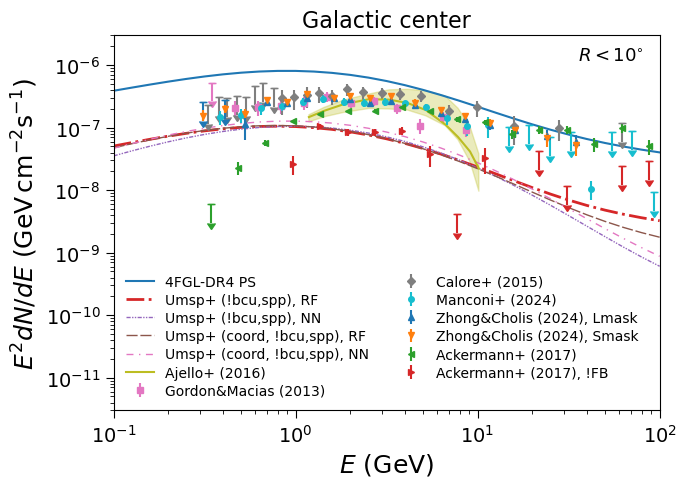

In [280]:
if plot_cases not in ['coord_cats']:
    add_scaled = True
else:
    add_scaled = False


if plot_cases == 'minimal':
    if case.find('no_bcu_spp') > -1:
        one_cat_cases = ['unas_cl', 'unas_unk_bcu_spp', 'unas_no_3FGL']
    else:
        one_cat_cases = ['unas_cl', 'unas_unk', 'unas_no_3FGL']
elif plot_cases == 'moriond':
    one_cat_cases = ['unas_cl']
    add_scaled = False
else:
    if case.find('no_bcu_spp') > -1:
        one_cat_cases = ['unas_cl', 'unas_unk_bcu_spp', 'unas_no_3FGL', 
                         'unas_no_3FGL_no_diff_flag', 'unas_no_3FGL_no_flag',
                        ]
    else:
        one_cat_cases = ['unas_cl', 'unas_unk', 'unas_no_3FGL', 
                         'unas_no_3FGL_no_diff_flag', 'unas_no_3FGL_no_flag',
                        ]
    if cl == 'psr':
        one_cat_cases.insert(1, 'unas_msp_psr')
        
#acl_cases = ['assoc_cl', 'assoc_cl_no_3FGL']
acl_cases = ['assoc_cl']
if cat_name == '4FGL-DR3':
    one_cat_cases = [case for case in one_cat_cases if case.find('no_3FGL') == -1]
    acl_cases = [case for case in acl_cases if case.find('no_3FGL') == -1]
    
many_cat_cases = []
for case_c in cat_dfs.keys():
    for alg_c in ['RF', 'NN']:
        many_cat_cases.append(case_c + '^' + alg_c)

#pyplot.figure()
ax = pyplot.subplot(111)

key = 'all_PS'
lsi = pinds[key]
pyplot.loglog(Es_plot, E2dNdE[key], ls=lss[lsi%len(lss)], color=colors[lsi%len(colors)], 
              label=plabels[key])

if add_scaled:
    if spatial_mask_type == 'R10':
        scaling = 8
    elif spatial_mask_type == 'S40_G4':
        scaling = 7
    pyplot.loglog(Es_plot, E2dNdE_all / scaling, 
                  #ls='--', 
                  ls=(0, (8, 4)),
                  color=colors[lsi%len(colors)], label='All PS / %i' % scaling)

key = 'unas_PS'
lsi = pinds[key]
if plot_cases not in ['coord_cats']:
    pyplot.loglog(Es_plot, E2dNdE[key], ls=lss[lsi%len(lss)], color=colors[lsi%len(colors)], 
                  label=plabels[key])

# plot models
if plot_cases not in ['many_cats', 'coord_cats']:
    for key in one_cat_cases:
        if key in pinds:
            lsi = pinds[key]
        else:
            lsi += 1
        if plot_cases == 'moriond' or key in ['unas_cl', 'unas_msp_psr']:
            lw = 2
        else:
            lw = 1
            
        if key == 'unas_msp_psr':
            pyplot.loglog(Es_plot, E2dNdE[key], ls=lss[lsi%len(lss)], lw=lw, 
                          color=colors[lsi%len(colors)], 
                          label=plabels[key])
        else:
            pyplot.loglog(Es_plot, E2dNdE[key], ls=lss[lsi%len(lss)], lw=lw, 
                          color=colors[lsi%len(colors)], 
                          label=plabels[key])
else:
    lsi += 1
    for key in many_cat_cases:
        if key in pinds:
            lsi = pinds[key]
        else:
            lsi += 1
            
        cat_key, alg_c = key.split('^')
        
        lw = 1
        if cat_key == '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' and alg_c == 'RF':
            lw = 2
        label = '%s, %s' % (plabels[cat_key], alg_c)
        pyplot.loglog(Es_plot, E2dNdE[key], ls=lss[lsi%len(lss)], lw=lw, 
                      color=colors[lsi%len(colors)], 
                      label=label)


# plot SEDs for associated sources
for k, key in enumerate(acl_cases):
    if key in pinds:
        lsi = pinds[key]
    else:
        lsi += 1
if plot_cases not in ['coord_cats']:
    pyplot.loglog(Es_plot, E2dNdE[key], ls=lss[lsi%len(lss)], lw=lw,
                  color=colors[lsi%len(colors)], label=plabels[key])

# plot GCE SEDs from references
sigma_ulim = 2.
cap_size = 3
rel_arr_length = 0.5
ms = 4
print(lsi)
lsi = 6
for key, dct in ref_dict.items():
    Es_ref = dct['med']['Energy']
    Fmed = dct['med']['E2dNdE']
    Fmin = dct.get('min', {}).get('E2dNdE')
    Fmax = dct.get('max', {}).get('E2dNdE')
    label = dct['label']
    color = colors[lsi%len(colors)]
    if dct['plot_type'] == 'error_bars':
        if Fmax is not None:
            err_up = Fmax - Fmed
        else:
            err_up = np.zeros_like(Fmed)
        if Fmin is not None:
            err_down = Fmed - Fmin
        elif Fmax is not None:
            err_down = err_up
        else:
            err_down = np.zeros_like(Fmed)
            
        if key.find('cholis') > -1:
            # Zhong & Cholis report 2 sigma band
            err_up /= 2.
            err_down /= 2.
        ulim_mask = get_ulim_mask(Fmed, err_up, sigma=sigma_ulim)
        errs = [err_up[~ulim_mask], err_down[~ulim_mask]]
        p = pyplot.errorbar(Es_ref[~ulim_mask], Fmed[~ulim_mask], errs, marker=mrks[lsi%len(mrks)], 
                            ms=ms, ls='', c=color, label=label)
        #color = p[0].get_color()
        F_ul = Fmed[ulim_mask] + sigma_ulim * err_up[ulim_mask]
        pyplot.errorbar(Es_ref[ulim_mask], F_ul, yerr=rel_arr_length * F_ul,
                        ls='', uplims=True, marker='_', ms=ms, c=color, capsize=cap_size)
        
    elif dct['plot_type'] == 'band':
        Es_ref_med = dct['med']['Energy']
        if Fmin is not None and Fmax is not None:
            pyplot.fill_between(Es_ref, Fmin, Fmax, ls='', color=color, alpha=0.3)
        pyplot.plot(Es_ref_med, Fmed, ls='-', color=color, label=label)
    lsi += 1
    

# GCE spectra from Ackermann et al 2017
for key, dct10 in F10_dict.items():
    print(key)
    FF = np.array(dct10['Flux'])
    FF_err = np.array(dct10['Flux_err'])
    if key == 'SCA_bubbles' and 0:
        marker = 'D'
        ms = 4
    else:
        marker = mrks[lsi%len(mrks)]
        ms = 4
    color = colors[lsi%len(colors)]
    #if key.find('bubbles') > -1:
    #    color = 'red'
    if FF_err.ndim == 2:
        ulim_mask = get_ulim_mask(FF, FF_err[1], sigma=sigma_ulim)
        p = pyplot.errorbar(Es_gce[~ulim_mask], FF[~ulim_mask], FF_err[:, ~ulim_mask], c=color, 
                        marker=marker, ms=ms, ls='', label=dct10['label'])
        #color = p[0].get_color()
        F_ul = FF[ulim_mask] + sigma_ulim * FF_err[1, ulim_mask]
        zero_mask = F_ul > 0
        pyplot.errorbar(Es_gce[ulim_mask][zero_mask], F_ul[zero_mask], yerr=rel_arr_length * F_ul[zero_mask],
                        ls='', uplims=True, marker='_', ms=ms, c=color, capsize=cap_size)
    else:
        ulim_mask = get_ulim_mask(FF, FF_err, sigma=sigma_ulim)
        p = pyplot.errorbar(Es_gce[~ulim_mask], FF[~ulim_mask], FF_err[~ulim_mask], c=color, 
                        marker=marker, ms=ms, ls='', label=dct10['label'])
        #color = p[0].get_color()
        F_ul = FF[ulim_mask] + sigma_ulim * FF_err[ulim_mask]
        zero_mask = F_ul > 0
        pyplot.errorbar(Es_gce[ulim_mask][zero_mask], F_ul[zero_mask], yerr=rel_arr_length * F_ul[zero_mask],
                        ls='', uplims=True, marker='_', ms=ms, c=color, capsize=cap_size)
    lsi += 1
    

pyplot.xlabel(r'$E\ (\rm GeV)$')
pyplot.ylabel(r'$E^2 dN/dE\ (\rm GeV\,cm^{-2} s^{-1})$')
pyplot.xlim(0.1, 100.)
if plot_cases == 'moriond':
    pyplot.ylim(3.e-11, 3.e-6)
elif spatial_mask_type == 'S40_G4':
    pyplot.ylim(3.e-11, 3.e-6)
else:
    pyplot.ylim(3.e-12, 3.e-6)
pyplot.legend(labelspacing=0.3, ncol=2, loc='lower left', frameon=0)
if plot_cases == 'flags':
    pyplot.legend(labelspacing=0.2, ncol=2, loc='lower left', columnspacing=0, frameon=0)
elif plot_cases == 'many_cats':
    pyplot.legend(labelspacing=0.2, ncol=2, loc='lower left', columnspacing=2, frameon=0)

pyplot.grid(visible=show_grid)
if plot_cases == 'minimal' and 0:
    if case.find('no_bcu_spp') > -1:
        txt = 'No bcu, spp in training'
        #pyplot.title('No bcu, spp in training')
    else:
        txt = 'With bcu, spp in training'
        #pyplot.title('With bcu, spp in training')
    pyplot.text(0.99, 0.97, txt, #fontsize=10, 
                #fontfamily='monospace', 
                horizontalalignment='right', verticalalignment='top',
                transform=ax.transAxes)

ytext = 0.97
xtext = 0.97
if spatial_mask_type == 'R10':
    ROI_str = r'$R < 10\!^\circ$'
elif spatial_mask_type == 'S40_G4':
    ROI_str = r'$|L|, |B| < 20\!^\circ$, $|B| > 2\!^\circ$'
else:
    ROI_str = ''
    
pyplot.text(xtext, ytext, ROI_str, fontsize=13, 
            #fontfamily='monospace', 
            horizontalalignment='right', verticalalignment='top',
            transform=ax.transAxes)

if show_title:
    pyplot.title('Galactic center')
if save_plots:
    fn = '%s/LP_spectrum_%s_%s.pdf' % (plots_folder, plot_cases, descr_str)
    if add_scaled:
        fn = '%s/LP_spectrum_%s_%s_with_scaled.pdf' % (plots_folder, plot_cases, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    fn_png = fn.replace('.pdf', '.png')
    #pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)


save figure to file: ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//W_evolution_coord_cats_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf
cp ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//W_evolution_coord_cats_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/4_msp_multi_gce/msp_multi_gce_git_PRD/plots/main//W_evolution_coord_cats_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf


/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_94728/1534802414.py:70: UserWarning: Unknown infodict keyword: 'Authors'. Must be one of {'Trapped', 'Keywords', 'Creator', 'Subject', 'CreationDate', 'ModDate', 'Title', 'Producer', 'Author'}.
  pyplot.savefig(fn, metadata=fig_meta)


0

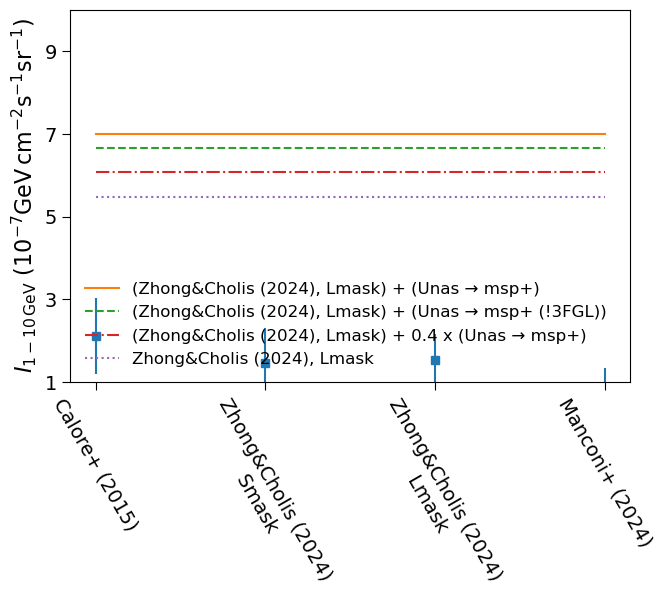

In [191]:

all_plots_pars0 = all_plots_pars.copy()

all_plots_pars = {'bottom':0.35, 'top':0.97, 'left':0.15, 'right':0.95}
fig_height = 6  # height in inches
fig_width = 7  # width in inches
fig_size =  [fig_width, fig_height]
all_plots_pars['fig_size'] = fig_size
all_plots_pars['axes.labelsize'] = 16
all_plots_pars['font.size'] = 15
all_plots_pars['legend.fontsize'] = 12

putil.setup_figure_pars(pars_dict=all_plots_pars)

key0 = '5_cholis_large'
power = 7
factor = 10**power
#pyplot.figure()
ax = pyplot.subplot(111)
msw = ['s', 'o']
xs = [0, len(gce_ws[0])-1]
xsw = np.arange(len(gce_ws[0]))
yy = factor * np.array(list(gce_ws[i].values())).T

for i in range(1):
    pyplot.errorbar(xsw, yy[0], yy[1:], ls='', marker=msw[i])

    for j, key in enumerate(wmspkeys):
        ys = np.ones(2) * (msp_ws[i][key][0] + gce_ws[i][key0][0])
        label = '(%s) + (%s)' % (ref_dict[key0]['label'], plabels[key])
        pyplot.plot(xs, factor * ys, ls=lss[j], label=label)
    key = 'unas_cl'
    ys = np.ones(2) * (0.4 * msp_ws[i][key][0] + gce_ws[i][key0][0])
    label = '(%s) + 0.4 x (%s)' % (ref_dict[key0]['label'], plabels[key])
    pyplot.plot(xs, factor * ys, ls='-.', label=label)

    ys = np.ones(2) * (gce_ws[i][key0][0])
    label = '%s' % (ref_dict[key0]['label'])
    pyplot.plot(xs, factor * ys, ls=':', label=label)
xlabels = [ref_dict[key]['label'].replace(',', '\n') for key in wkeys]
pyplot.xticks(ticks=np.arange(len(gce_ws[0])), labels=xlabels, rotation=-60)
ymin = 1
ymax = 10
yshift = 0.5
pyplot.ylim(ymin, ymax)
pyplot.yticks(ticks=np.arange(ymin, ymax + 1, 2))
pyplot.legend(loc='lower left', frameon=0)
pyplot.ylabel(r'$I_{1 - 10\, {\rm GeV}}\ (\rm 10^{-%i} GeV\,cm^{-2} s^{-1} sr^{-1})$' % power)

if spatial_mask_type == 'R10':
    ROI_str = r'$R < 10\!^\circ$'
elif spatial_mask_type == 'S40_G4':
    ROI_str = r'$|L|, |B| < 20\!^\circ$, $|B| > 2\!^\circ$'
else:
    ROI_str = ''

if 0:
    ytext = 0.97
    xtext = 0.97
    pyplot.text(xtext, ytext, ROI_str, fontsize=13, 
                #fontfamily='monospace', 
                horizontalalignment='right', verticalalignment='top',
                transform=ax.transAxes)


if save_plots:
    fn = '%s/W_evolution_%s_%s.pdf' % (plots_folder, plot_cases, descr_str)
    if add_scaled:
        fn = '%s/W_evolution_%s_%s_with_scaled.pdf' % (plots_folder, plot_cases, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    fn_png = fn.replace('.pdf', '.png')
    #pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)
        
all_plots_pars = all_plots_pars0.copy()
putil.setup_figure_pars(pars_dict=all_plots_pars)

In [192]:
gce_ws

{0: {'4_Calore': [7.184669359798282e-07,
   1.6929181141067837e-07,
   1.7676851983215713e-07],
  '5_cholis_small': [6.090185986104479e-07,
   1.2568646350280928e-07,
   1.0862678487600409e-07],
  '5_cholis_large': [5.485598301416973e-07,
   1.2707078902306734e-07,
   1.0767057348387723e-07],
  '6_manconi': [5.167879254844718e-07,
   8.021491682310881e-08,
   8.021491682310881e-08]},
 1: {'4_Calore': [2.1107590338367363e-07,
   9.196563044581898e-08,
   9.172945995962333e-08],
  '5_cholis_small': [1.4617641584283491e-07,
   6.585581652038728e-08,
   8.381878218408429e-08],
  '5_cholis_large': [1.5384122613647435e-07,
   8.132694826941206e-08,
   6.235297649286996e-08],
  '6_manconi': [8.081383207493013e-08,
   5.3738211911377e-08,
   5.3738211911377e-08]}}

In [193]:
if 0:
    Etest = 2.
    ind_test = np.argmin(np.abs(Es_plot - Etest))
    #np.max(E2dNdE), np.max(E2dNdE_assoc)
    E2dNdE[ind_test], E2dNdE_assoc[ind_test]

In [194]:
# radial profile of intensity
qs = ['N', 'S', 'E', 'W']
mask_gal_plane = False
if mask_gal_plane:
    Bgmax = 2
    rs = np.arange(2.5, 41., 2.5)
else:
    Bgmax = 0
    rs = np.arange(0., 41., 2.5)
rc = (rs[1:] + rs[:-1])/2.
nr = len(rc)
int_dict = {qn: np.zeros_like(rc) for qn in qs}
Bs = df_extra['GLAT']
Ls = df_extra['GLON']


In [195]:
ptype = 'unas' # 'unas', 'assoc', 'all', 'unas_not_3FGL', 'unas_not_3FGL_no_diff_flag'
if ptype == 'unas':
    smask = unas_mask
if ptype == 'assoc':
    smask = cl_mask
if ptype == 'all':
    smask = True
if ptype == 'unas_not_3FGL':
    smask = unas_mask & mask_3FGL
if ptype == 'unas_not_3FGL_no_diff_flag':
    smask = unas_mask & mask_3FGL & flag_mask_diff

sp_tot = 0. # consistency check
Es_int = np.array([2.]) # intensity profile at 2 GeV
if mask_gal_plane:
    gmask = ~mask_rect(Bs, Ls, Bmin=-Bgmax, Bmax=Bgmax, Lmin=-180, Lmax=180)
for i in range(nr):
    area0 = ring_area_sr(R_max=rs[i+1], R_min=rs[i], phi=90.)
    area_dict = {qn:area0 for qn in qs}
    if mask_gal_plane:
        for qn in ['E', 'W']:
            area_dict[qn] -= np.deg2rad(1)**2 * (rs[i+1] - rs[i]) * 2 * Bgmax
    for qn in qs:
        mask = mask_quad_ring(Bs, Ls, R_max=rs[i+1], R_min=rs[i], qname=qn) & smask
        if mask_gal_plane:
            mask &= gmask
        LP_spectra = get_LP_spectra(mask, Es_plot=Es_int, Eind=2.)
        if ptype.find('unas') > -1:
            weights = get_weights(cat_df, cl_inds, alg, mask)
        else:
            weights = 1.
        E2dNdE = np.sum(weights * LP_spectra.T)
        sp_tot += E2dNdE
        int_dict[qn][i] = E2dNdE / area_dict[qn]

In [196]:
if 0:
    # test the quadrant mask
    tmask = mask_quad_ring(Bs, Ls, R_max=rs[i+1], R_min=rs[i], qname='E')
    print(Ls[tmask][:5]) # should be positive
    print(Bs[tmask][:5]) # and larger than Bs

In [197]:
int_dict_sum = {}
int_dict_sum['East + West'] = (int_dict['E'] + int_dict['W']) / 2.
int_dict_sum['North + South'] = (int_dict['N'] + int_dict['S']) / 2.
int_dict_sum['All quadrants'] = np.mean([int_dict[qn] for qn in qs], axis=0)
qss = int_dict_sum.keys()

In [198]:
alpha = 1.25
fudge = 1.
N0 = np.max([int_dict[qn][0] for qn in qs])
profile = fudge * N0 * (rc[0] / rc)**(2 * alpha - 1)

In [199]:
ref_profiles_folder = '/Users/Dmitry/Work/Fermi/gcfit/GC_excess_external_spectra/profiles/'
fn = '%s/Brand_Kocsis_Rprofile.txt' % ref_profiles_folder
rpdata = np.loadtxt(fn).T

profile_dict = {}
profile_dict['BrandKocsis'] = {}
profile_dict['BrandKocsis']['psi'] = rpdata[0]
profile_dict['BrandKocsis']['med'] = rpdata[1]
profile_dict['BrandKocsis']['max'] = rpdata[1] * 2.
profile_dict['BrandKocsis']['min'] = rpdata[1] / 2.
profile_dict['BrandKocsis']['label'] = 'Brandt & Kocsis (2015)'
profile_dict['BrandKocsis']['color'] = 'y'
profile_dict['BrandKocsis']['plot_type'] = 'band'

In [200]:
# GCE paper SOM profile
SOM_folder = '/Users/Dmitry/Work/Fermi/gcfit/results/SOM/'
fn = SOM_folder + 'fig20_radial_profile.yaml'
SOM_profile_dict = dio3.loaddict(fn)
gce_labels = {'GC excess (NFW gamma = 1)': r'Ackermann+ (2017) (NFW annihilation)', 
              'GC excess (gNFW gamma = 1.25)': r'Ackermann+ (2017) (gNFW $\gamma = 1.25$)'}

In [201]:
ptype

'unas'

In [202]:
int_dict_sum

{'East + West': array([2.61794215e-06, 1.34420093e-06, 1.00550517e-06, 5.14176539e-07,
        3.91630951e-07, 3.05184644e-07, 3.26800088e-07, 3.77764991e-07,
        2.32334526e-07, 2.50026703e-07, 4.07986177e-07, 2.72648867e-07,
        1.41237057e-07, 1.50670361e-07, 1.31786017e-07, 8.87430395e-08]),
 'North + South': array([2.68031001e-06, 1.74440117e-06, 6.21990358e-07, 3.42217589e-07,
        1.60091205e-07, 5.70700281e-08, 5.59447050e-08, 5.78940901e-08,
        3.49406384e-08, 7.51273110e-09, 6.22459796e-08, 2.03186365e-08,
        5.56615655e-09, 1.64742989e-08, 6.10133302e-09, 2.86981971e-08]),
 'All quadrants': array([2.64912608e-06, 1.54430105e-06, 8.13747764e-07, 4.28197064e-07,
        2.75861078e-07, 1.81127336e-07, 1.91372396e-07, 2.17829541e-07,
        1.33637582e-07, 1.28769717e-07, 2.35116078e-07, 1.46483752e-07,
        7.34016069e-08, 8.35723299e-08, 6.89436748e-08, 5.87206183e-08])}

save figure to file: ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//Radial_profile_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf
cp ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//Radial_profile_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/4_msp_multi_gce/msp_multi_gce_git_PRD/plots/main//Radial_profile_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf


/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_94728/897023309.py:119: UserWarning: Unknown infodict keyword: 'Authors'. Must be one of {'Trapped', 'Keywords', 'Creator', 'Subject', 'CreationDate', 'ModDate', 'Title', 'Producer', 'Author'}.
  pyplot.savefig(fn, metadata=fig_meta)


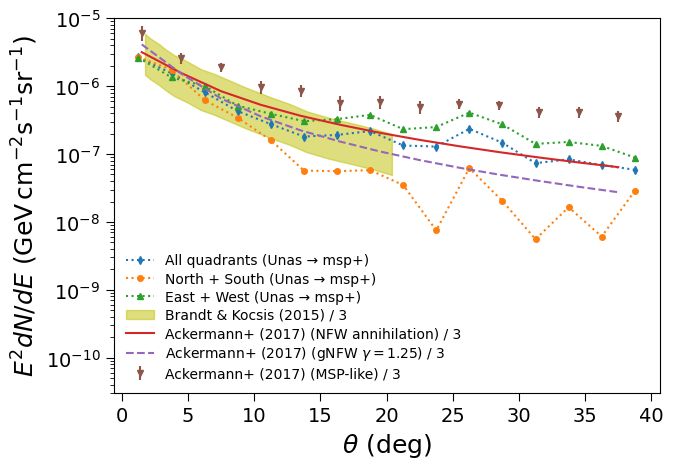

In [203]:
ms = 4
add_gce_SOM = 1
if ptype == 'unas_not_3FGL_no_diff_flag':
    renorm_ref = 3 # 1.
    renorm_amsp = 3
else:
    renorm_ref = 3
    renorm_amsp = 3

#pyplot.figure()
ax = pyplot.subplot(111)
lsi = 0
if 1:
    #label = ''
    label = 'All quadrants '
    if ptype == 'unas_not_3FGL':
        label += '(Unas %s %s, !3FGL)' % (right_arrow(), cl_str)
    elif ptype == 'unas_not_3FGL_no_diff_flag':
        label += '(Unas %s %s, !3FGL, !diff flags)' % (right_arrow(), cl_str)
    else:
        label += '(Unas %s %s)' % (right_arrow(), cl_str)
    pyplot.semilogy(rc, int_dict_sum['All quadrants'], ls=':', 
                    marker=mrks[lsi%len(mrks)], ms=ms, label=label)
    lsi += 1    
if 1:
    quads = ['North + South', 'East + West']
    for qn in quads:
        #pyplot.semilogy(rc, int_dict[qn], ls='-', marker='s', ms=3, label=qn)
        label = '%s' % qn
        if ptype == 'unas_not_3FGL':
            label += ' (Unas %s %s, !3FGL)' % (right_arrow(), cl_str)
        elif ptype == 'unas_not_3FGL_no_diff_flag':
            label += '(Unas %s %s, !3FGL, !diff flags)' % (right_arrow(), cl_str)
        else:
            label += ' (Unas %s %s)' % (right_arrow(), cl_str)
        pyplot.semilogy(rc, int_dict_sum[qn], ls=':', marker=mrks[lsi%len(mrks)], ms=ms, label=label)
        lsi += 1
if 0:
    quads = ['North', 'South', 'East', 'West']
    for qn in quads:
        #pyplot.semilogy(rc, int_dict[qn], ls='-', marker='s', ms=3, label=qn)
        label = '%s' % qn
        if ptype == 'unas_not_3FGL':
            label += ' (Unas %s %s, !3FGL)' % (right_arrow(), cl_str)
        else:
            label += ' (Unas %s %s)' % (right_arrow(), cl_str)
        pyplot.semilogy(rc, int_dict[qn[0]], ls=':', marker=mrks[lsi%len(mrks)], 
                        ms=ms, label=label)
        lsi += 1
    
for dct in profile_dict.values():
    if dct.get('plot_type', 'band') == 'band':
        xs = dct['psi']
        ymin = dct['min']
        ymax = dct['max']
        color = dct['color']
        label = dct['label']
        if renorm_ref != 1.:
            label += ' / %i' % renorm_ref
        pyplot.fill_between(xs, ymin / renorm_ref, ymax / renorm_ref, 
                            color=color, alpha=0.5, label=label)
    else:
        pyplot.plot()
if add_gce_SOM:
    xs = SOM_profile_dict['Radius']
    igce = 0
    for key, label in gce_labels.items():
        ys = np.array(SOM_profile_dict[key]) / renorm_ref
        if renorm_ref != 1.:
            label += ' / %i' % renorm_ref
        pyplot.semilogy(xs, ys, ls=lss[igce%len(lss)], label=label)
        igce += 1
    key = 'MSP-like component'
    ys = np.array(SOM_profile_dict[key]) / renorm_amsp
    ys_err = np.array(SOM_profile_dict[key + ' stat err']) / renorm_amsp
    label = 'Ackermann+ (2017) (MSP-like)'
    if renorm_ref != 1.:
        label += ' / %i' % renorm_amsp
    pyplot.errorbar(xs, ys, ys_err, ls='', marker=mrks[lsi%len(mrks)], ms=ms, label=label)

    
if 0:
    pyplot.text(0.99, 0.97, txt, #fontsize=10, 
                #fontfamily='monospace', 
                horizontalalignment='right', verticalalignment='top',
                transform=ax.transAxes)


#pyplot.semilogy(rc, profile, ls='--', label=r'$1/r^{%.2f}$ DM profile' % alpha)
pyplot.legend(labelspacing=0.3, ncol=1, fontsize=10, frameon=0)
pyplot.grid(visible=show_grid)

if ptype == 'unas_not_3FGL_no_diff_flag':
    pyplot.ylim(3.e-11, 1.e-5)
else:
    pyplot.ylim(3.e-11, 1.e-5)
pyplot.xlabel(r'$\theta\ (\rm deg)$')
pyplot.ylabel(r'$E^2 dN/dE\ (\rm GeV\,cm^{-2} s^{-1} sr^{-1})$')

if mask_gal_plane:
    ROI_txt = r'$|b| > 2\!^\circ$'
    ytext = 0.95
    xtext = 0.95
    pyplot.text(xtext, ytext, ROI_txt, fontsize=13, 
                #fontfamily='monospace', 
                horizontalalignment='right', verticalalignment='top',
                transform=ax.transAxes)
    ROI_str = '_mask_GP%i' % Bgmax
else:
    ROI_str = ''


if save_plots:
    if ptype == 'unas':
        fn = '%s/Radial_profile_%s%s.pdf' % (plots_folder, descr_str, ROI_str)
    else:
        fn = '%s/Radial_profile_%s_%s%s.pdf' % (plots_folder, descr_str, ptype, ROI_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    fn_png = fn.replace('.pdf', '.png')
    #pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex and case == '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp':
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)


In [204]:
ms

4

In [205]:
int_dict

{'N': array([2.91230669e-06, 1.62604476e-06, 3.80819936e-07, 1.55135036e-07,
        1.86529481e-07, 2.50750381e-08, 5.56369766e-08, 3.89615002e-08,
        4.59881038e-08, 1.02689591e-08, 9.42141057e-08, 3.87184211e-08,
        5.83632560e-09, 2.20720257e-08, 8.62014268e-09, 3.42065174e-08]),
 'S': array([2.44831332e-06, 1.86275759e-06, 8.63160780e-07, 5.29300141e-07,
        1.33652929e-07, 8.90650182e-08, 5.62524333e-08, 7.68266800e-08,
        2.38931731e-08, 4.75650307e-09, 3.02778535e-08, 1.91885202e-09,
        5.29598750e-09, 1.08765722e-08, 3.58252336e-09, 2.31898768e-08]),
 'E': array([2.16283777e-07, 1.32192408e-06, 1.13874993e-06, 5.01099663e-07,
        3.25647457e-07, 1.55364235e-07, 3.32218107e-07, 3.63724940e-07,
        2.20253835e-07, 2.25078479e-07, 3.11588799e-07, 2.57593108e-07,
        1.75229956e-07, 2.46241780e-07, 1.18974099e-07, 7.20411145e-08]),
 'W': array([5.01960052e-06, 1.36647778e-06, 8.72260406e-07, 5.27253416e-07,
        4.57614445e-07, 4.55005052e-07

In [206]:
pinds

{'all_PS': 0,
 'all_PS_allsky': 0,
 'unas_PS': 1,
 'unas_PS_allsky': 1,
 'unas_cl': 3,
 'unas_cl_allsky': 3,
 'assoc_cl': 2,
 'assoc_cl_allsky': 2,
 'unas_msp_psr': 6,
 'unas_msp_psr_allsky': 6,
 'unas_unk_bcu_spp': 4,
 'unas_unk_bcu_spp_allsky': 4,
 'unas_no_3FGL': 5,
 'unas_no_3FGL_allsky': 5,
 'GLC': 6,
 'Disk': 7,
 'unas_no_3FGL_no_diff_flag': 8,
 'unas_no_3FGL_no_flag': 9}

In [207]:
# flux distribution
binsdec = 7 # Slatyer et al = 7
bins = np.logspace(-12, -10, 2 * binsdec + 1)
eflux_centers = (bins[1:] + bins[:-1]) / 2.
EFhists = {}

# all PS
vs = df_extra['Energy_Flux100'][spat_mask]
EFhists['all_PS'] = np.histogram(vs, bins=bins)[0]

# unas PS
vs = df_extra['Energy_Flux100'][spat_mask & unas_mask]
EFhists['unas_PS'] = np.histogram(vs, bins=bins)[0]

# assoc msp contribution
vs = df_extra['Energy_Flux100'][amask]
EFhists['assoc_cl'] = np.histogram(vs, bins=bins)[0]



for key, umask in umasks.items():
    weights = get_weights(cat_df, cl_inds, alg, umask)
    vs = df_extra['Energy_Flux100'][umask]
    EFhists[key] = np.histogram(vs, bins=bins, weights=weights)[0]
    
if cl == 'psr':
    umask = umasks['unas_all']
    weights = get_weights(cat_df, cl_inds_mp, alg, umask)
    vs = df_extra['Energy_Flux100'][umask]
    EFhists['unas_msp_psr'] = np.histogram(vs, bins=bins, weights=weights)[0]


    weights = get_weights(cat_df, [get_cl_ind(dec_tree_cat_dict, 'msp')], alg, umask)
    vs = df_extra['Energy_Flux100'][umask]
    EFhists['unas_msp'] = np.histogram(vs, bins=bins, weights=weights)[0]


In [208]:
# external data
# Slatyer et al
folder = '/Users/Dmitry/Work/Fermi/fermi_multiclass/data_in/2112.09699/data/'
sdfs = {}
for key in ['GLC', 'Disk']:
    fn = folder + 'fig_9a_%s.csv' % key
    sdfs[key] = pd.pandas.read_csv(fn, delimiter=',', index_col=None)
sflux_col_name = sdfs[key].columns[0]

In [209]:
EFhists.keys()

dict_keys(['all_PS', 'unas_PS', 'assoc_cl', 'unas_unk_bcu_spp', 'unas_cl', 'unas_no_3FGL', 'unas_no_3FGL_no_diff_flag', 'unas_no_3FGL_no_flag', 'unas_all'])

4FGL-DR4 PS 285
Unas 4FGL-DR4 PS 198
Unas, unk, bcu, spp → msp+ 100.43513846083398
Unas → msp+ (!3FGL) 72.74575125554158
Unas → msp+ 84.81958097507503
Assoc msp+ 12
Dinsmore&Slatyer, GLC 6
Dinsmore&Slatyer, Disk 7
save figure to file: ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//luminosity_coord_cats_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf


/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_94728/309244963.py:71: UserWarning: Unknown infodict keyword: 'Authors'. Must be one of {'Trapped', 'Keywords', 'Creator', 'Subject', 'CreationDate', 'ModDate', 'Title', 'Producer', 'Author'}.
  pyplot.savefig(fn, metadata=fig_meta)


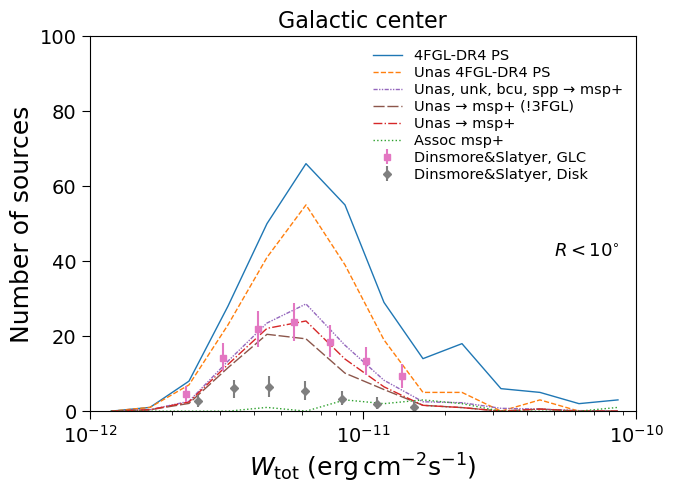

In [210]:
hist_cases = ['all_PS', 'unas_PS', 'unas_unk_bcu_spp', 'unas_no_3FGL', 'unas_cl', 'assoc_cl']
if plot_cases == 'flags':
    hist_cases.extend(['unas_no_3FGL_no_diff_flag', 'unas_no_3FGL_no_flag',])
if cl == 'psr':
    if 'unas_msp_psr' not in hist_cases:
        hist_cases.append('unas_msp_psr')
    
add_ref_Fs = True
msr = 4
if plot_cases == 'moriond':
    lw = 2
else:
    lw = 1


#pyplot.figure()
ax = pyplot.subplot(111)

for key in hist_cases:    
    ms = 0
    #if key == 'unas_cl' and plot_cases != 'moriond':
    #    ms = 7
    lsi = pinds[key]
    pyplot.semilogx(eflux_centers, EFhists[key], ls=lss[lsi%len(lss)], 
                    marker=mrks[lsi%len(mrks)], ms=ms, lw=lw,
                 c=colors[lsi%len(colors)], label=plabels[key])
    print(plabels[key], np.sum(EFhists[key]))


if add_ref_Fs:
    for key, sdf in sdfs.items():
        lsi = pinds[key]
        xs = 1.e-12 * sdf[sflux_col_name]
        ys = sdf['Med']
        err_down = ys - sdf['Min']
        err_up = sdf['Max'] - ys
        label = 'Dinsmore&Slatyer, %s' % key
        pyplot.errorbar(xs, ys, [err_down, err_up], ls='', 
                        marker=mrks[lsi%len(mrks)], ms=msr, 
                        c=colors[(lsi)%len(colors)], label=label)
        print(label, lsi)
    #fdown = 2
    #pyplot.errorbar(xs, ys/fdown, [err_down/np.sqrt(fdown), err_up/np.sqrt(fdown)], 
    #                ls='', marker='o', ms=msr, label='GLC model / %i' % fdown)
xtext = 0.85
if plot_cases == 'minimal':
    ytext = 0.5
else:
    ytext = 0.45
ROI_str = r'$R < 10\!^\circ$'
pyplot.text(xtext, ytext, ROI_str, fontsize=13, 
            #fontfamily='monospace', 
            horizontalalignment='left', verticalalignment='top',
            transform=ax.transAxes)

pyplot.grid(visible=show_grid)
pyplot.legend(labelspacing=0.2, ncol=1, fontsize=10.5, frameon=0)
pyplot.xlabel(r'$W_{\rm tot}\ (\rm erg\,cm^{-2} s^{-1})$')
pyplot.ylabel('Number of sources')
pyplot.xlim(1.e-12, 1.e-10)
pyplot.ylim(0, 100)
if show_title:
    pyplot.title('Galactic center')

#copy2tex = 1
#save_plots = 0

if save_plots:
    fn = '%s/luminosity_%s_%s.pdf' % (plots_folder, plot_cases, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    fn_png = fn.replace('.pdf', '.png')
    #pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex and case == '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' and plot_cases in ['minimal', 'flags', 'moriond']:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

In [211]:
# plot the integrated flux distribution S dN/dS
#Splot_keys = ['unas_all']
#Es_plotF = np.logspace(-1., 2., 15)
def get_LP_spectra(mask, Es_plot=Es_plot, Eind=2.):
    sps = log_par_sp(Es_plot, E0, indE0[mask], beta[mask], norm=LP_norm[mask], same_dim=False)
    return Es_plot**Eind * sps

Stype = '10degR' # '10degR', '30degR'
ext_SdNdS = {}
ext_SdNdS_err = {}
ext_labels = {'Leane':'Leane&Slatyer (2019)',
             'Buschmann': 'Buschmann et al. (2020)',
             'Calore': 'Calore et al. (2021)'}
Sfolder = '../../data_in/dNdS/data/'
nyear = 14
Area_allsky = 4. * np.pi * np.rad2deg(1.)**2
Area_allsky_sr = 4. * np.pi
if Stype == '10degR':
    Emin = 2.
    Emax = 5.
    nbins = 10
    spat_maskS = (np.abs(df_extra['GLAT']) > 2.) & (np.abs(df_extra['GLAT']) < 10.)
    spat_maskS &= np.abs(df_extra['GLON']) < 10.
    ROI_str = r'$|\ell| < 10\!^\circ$' + '\n' + r'$2\!^\circ < |b| < 10\!^\circ$'
    
    width = 20.
    height = 20. - 4.
    Area_c = width * height
    Area = Area_c
    fn = Sfolder + 'Calore_etal_GCE_1pt_PDF_2102.12497v2_Fig1.csv'
    ext_SdNdS['Calore'] = get_SdNdS(fn, kind=1)
    fn = Sfolder + 'Calore_etal_GCE_1pt_PDF_2102.12497v2_Fig1_upper.csv'
    ext_SdNdS_err['Calore'] = {}
    ext_SdNdS_err['Calore']['up'] = get_SdNdS(fn, kind=2)
    fn = Sfolder + 'Calore_etal_GCE_1pt_PDF_2102.12497v2_Fig1_lower.csv'
    ext_SdNdS_err['Calore']['down'] = get_SdNdS(fn, kind=2)
    
    if 0:
        fn = Sfolder + 'Buschmann_etal_2002.12373v1_Fig16.csv'
        data = np.loadtxt(fn, delimiter=',').T
        R = 10
        h = 2
        Area_b = np.pi * R**2 - h * 2 * R
        ff_b = interp1d(data[0], data[1], kind=1, fill_value="extrapolate")
        def SdNdS_b(S):
            log10S = np.log10(S)
            log10F = -log10S + ff_b(log10S) #+ np.log10(Area_c)
            return 10**(log10F)
        ext_SdNdS['Buschmann'] = SdNdS_b

elif Stype == '30degR':
    #nyear = 8
    Emin = 2.
    Emax = 20.
    nbins = 15
    R_max = 30.
    h = 2.
    Area = np.pi * R_max**2 - h * 2 * R_max
    spat_maskS = mask_circle(df_extra['GLAT'], df_extra['GLON'], R_max)
    spat_maskS &= (np.abs(df_extra['GLAT']) > h)
    ROI_str = r'$R < 30\!^\circ$' + '\n' + r'$|b| > 2\!^\circ$'
    
    fn = Sfolder + 'Leane_Slatyer_1904.08430v1_FigS4a.csv'
    ext_SdNdS['Leane'] = get_SdNdS(fn, kind=2, n0=0)
    R = 30
    h = 2
    Area_l = np.pi * R**2 - h * 2 * R
    
    fn = Sfolder + 'Buschmann_etal_2002.12373v1_Fig7.csv'
    ext_SdNdS['Buschmann'] = get_SdNdS(fn, kind=1, n0=2)
    R = 25
    h = 2
    Area_b = np.pi * R**2 - h * 2 * R
    
Es_plotFb = np.logspace(np.log10(Emin), np.log10(Emax), nbins)
Es_plotF = np.sqrt(Es_plotFb[1:] * Es_plotFb[:-1])
dEs_plotF = Es_plotFb[1:] - Es_plotFb[:-1]
SdNdS = {}
log10Smin = -11
log10Smax = -8
Sb = np.logspace(log10Smin, log10Smax, 31)
Sc = np.sqrt(Sb[1:] * Sb[:-1])
dS = Sb[1:] - Sb[:-1]

Sbext = np.logspace(log10Smin, log10Smax, 200)
Scext = np.sqrt(Sbext[1:] * Sbext[:-1])


umaskS = spat_maskS & unas_mask
weights = get_weights(cat_df, cl_inds, alg, umaskS)
LP_spectra = get_LP_spectra(umaskS, Es_plot=Es_plotF, Eind=0.)
S_unas = np.sum(LP_spectra * dEs_plotF, axis=1)
SdNdS['unas_PS'] = Sc * np.histogram(S_unas, bins=Sb)[0] / dS / Area
SdNdS['unas_cl'] = Sc * np.histogram(S_unas, weights=weights, bins=Sb)[0] / dS
SdNdS['unas_cl'] /= Area

if 1:
    LP_spectra = get_LP_spectra(np.ones_like(unas_mask), Es_plot=Es_plotF, Eind=0.)
    S_all = np.sum(LP_spectra * dEs_plotF, axis=1)
    SdNdS['all_PS_allsky'] = Sc * np.histogram(S_all, bins=Sb)[0] / dS / Area_allsky_sr

    umaskS_allsky = unas_mask
    weights_allsky = get_weights(cat_df, cl_inds, alg, umaskS_allsky)
    LP_spectra = get_LP_spectra(umaskS_allsky, Es_plot=Es_plotF, Eind=0.)
    S_unas = np.sum(LP_spectra * dEs_plotF, axis=1)
    SdNdS['unas_PS_allsky'] = Sc * np.histogram(S_unas, bins=Sb)[0] / dS / Area_allsky_sr
    SdNdS['unas_cl_allsky'] = Sc * np.histogram(S_unas, weights=weights_allsky, bins=Sb)[0]
    SdNdS['unas_cl_allsky'] /= dS * Area_allsky_sr


In [212]:
#E2dNdE_cl = {}
key = 'assoc_cl'
aclmaskS = cl_mask & spat_maskS
LP_spectra = get_LP_spectra(aclmaskS, Es_plot=Es_plotF, Eind=0.)
S_cl = np.sum(LP_spectra * dEs_plotF, axis=1)
SdNdS[key] = Sc * np.histogram(S_cl, bins=Sb)[0] / dS / Area
print('There are %i MSP+ sources in the GC ROI:' % sum(aclmaskS))
print(cat_df[aclmaskS]['CLASS1'])

if 1:
    key = 'assoc_cl_allsky'
    aclmaskS = cl_mask
    LP_spectra = get_LP_spectra(aclmaskS, Es_plot=Es_plotF, Eind=0.)
    S_cl = np.sum(LP_spectra * dEs_plotF, axis=1)
    SdNdS[key] = Sc * np.histogram(S_cl, bins=Sb)[0] / dS / Area_allsky_sr
    print('There are %i MSP+ sources in the full sky' % sum(aclmaskS))

key = 'all_PS'
LP_spectra = get_LP_spectra(spat_maskS, Es_plot=Es_plotF, Eind=0.)
S_cl = np.sum(LP_spectra * dEs_plotF, axis=1)
SdNdS[key] = Sc * np.histogram(S_cl, bins=Sb)[0] / dS / Area


There are 13 MSP+ sources in the GC ROI:
4FGL J1649.8-3010    msp
4FGL J1701.2-3006    glc
4FGL J1714.2-2928    glc
4FGL J1716.7-2808    glc
4FGL J1727.6-3050    glc
4FGL J1730.8-2303    msp
4FGL J1731.7-1850    msp
4FGL J1747.7-4037    msp
4FGL J1748.9-2021    glc
4FGL J1750.3-3702    glc
4FGL J1811.3-2403    msp
4FGL J1823.5-3020    msp
4FGL J1824.6-2452    msp
Name: CLASS1, dtype: object
There are 244 MSP+ sources in the full sky


In [213]:
np.max(list(pinds.values()))

9

all_PS 227.0
unas_PS 169.0
unas_cl 78.28345515796154
assoc_cl 13.0
Calore 0.6718745848934605 6.865677777260385e-11
save figure to file: ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//SdNdS_10degR_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf


/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_94728/398832798.py:96: UserWarning: Unknown infodict keyword: 'Authors'. Must be one of {'Trapped', 'Keywords', 'Creator', 'Subject', 'CreationDate', 'ModDate', 'Title', 'Producer', 'Author'}.
  pyplot.savefig(fn, metadata=fig_meta)


cp ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//SdNdS_10degR_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/4_msp_multi_gce/msp_multi_gce_git_PRD/plots/main//SdNdS_10degR_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf


<Figure size 700x500 with 0 Axes>

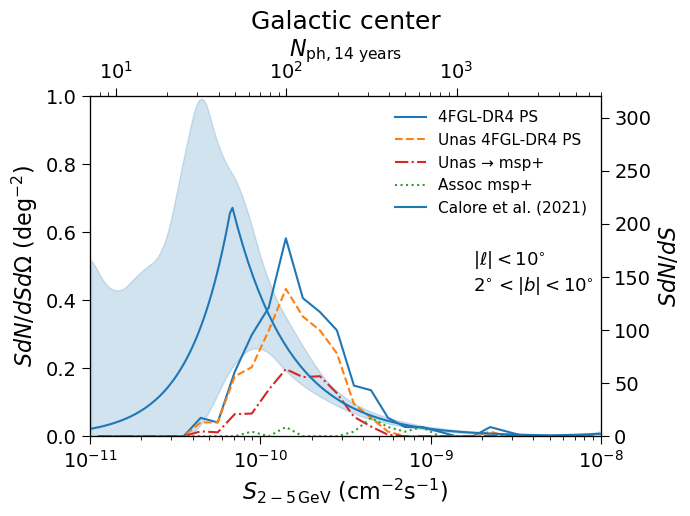

In [214]:
show_grid = 0
show_title = 1
if show_title:
    top = 0.82
else:
    top = 0.86
all_plots_pars = {'bottom':0.14, 'top':top, 'left':0.13, 'right':0.86}
fig_height = 5   # height in inches
fig_width = 7  # width in inches
fig_size =  [fig_width, fig_height]
all_plots_pars['fig_size'] = fig_size
all_plots_pars['axes.titlesize'] = 18
all_plots_pars['axes.labelsize'] = 16
all_plots_pars['font.size'] = 13
all_plots_pars['legend.fontsize'] = 11
putil.setup_figure_pars(pars_dict=all_plots_pars)


msr = 5
#color = colors[lsi%len(colors)]

pyplot.figure()
fig, ax1 = pyplot.subplots()

for key in ['all_PS', 'unas_PS', 'unas_cl', 'assoc_cl']:
    lsi = pinds[key]
    pyplot.semilogx(Sc, SdNdS[key], ls=lss[lsi%len(lss)], c=colors[lsi%len(colors)], 
                    label=plabels[key])
    print(key, sum(SdNdS[key]*dS/Sc*Area))


lsi = np.max(list(pinds.values()))
for key, f in ext_SdNdS.items():
    lsi += 1
    lns = ax1.semilogx(Scext, f(Scext), ls=lss[lsi%len(lss)], c=colors[lsi%len(colors)], 
                    label=ext_labels[key])
    if key in ext_SdNdS_err:
        color = lns[0].get_color()
        up = ext_SdNdS_err[key]['up']
        down = ext_SdNdS_err[key]['down']
        ax1.fill_between(Scext, down(Scext), up(Scext), color=color, alpha=0.2)
    ind = np.argmax(f(Scext))
    print(key, np.max(f(Scext)), Scext[ind])
    
if Stype == '10degR':
    if 1:
        ymin = 0.0
        ymax = 1.
    else:
        ymin = 0.005
        ymax = 2.
    xtext = 0.75
    ytext = 0.55
    
if Stype == '30degR':
    ymin = 0.
    ymax = 0.5
    xtext = 0.8
    ytext = 0.45
    
ax1.set_ylim(ymin, ymax)
ax1.set_xlim(10**log10Smin, 10**log10Smax)
pyplot.legend(frameon=0)
ax1.set_xlabel(r'$S_{\rm %i - %i\, {\rm GeV}}\ (\rm cm^{-2} s^{-1})$' % (Emin, Emax))
ax1.set_ylabel(r'$S dN/dSd\Omega\ (\rm deg^{-2})$')
if show_title:
    pyplot.title('Galactic center')

pyplot.text(xtext, ytext, ROI_str, #fontsize=14, 
            #fontfamily='monospace', 
            horizontalalignment='left', verticalalignment='top',
            transform=ax1.transAxes)
if show_grid:
    ax1.grid()
ax2 = ax1.twinx()
ax2.set_ylabel(r'$S dN/dS$')
ax2.set_ylim(ymin * Area, ymax * Area)
ax3 = ax1.twiny()
ax3.set_xlabel(r'$N_{\rm ph, %i\ years}$' % nyear)
xmin = 10**log10Smin * exposure(nyear)
xmax = 10**log10Smax * exposure(nyear)
ax3.set_xlim(xmin, xmax)
ax3.set_xscale('log')

if 0:
    ax1.set_yscale('log')
    ax2.set_yscale('log')
    ax3.set_yscale('log')

#ax3.set_xlim(ymin * Area, ymax * Area)
#copy2tex = 0
#save_plots = 0
if save_plots:
    fn = '%s/SdNdS_%s_%s.pdf' % (plots_folder, Stype, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    fn_png = fn.replace('.pdf', '.png')
    pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

In [215]:
91./118

0.7711864406779662

all_PS_allsky 233.80034852402412
unas_PS_allsky 82.4163470460793
unas_cl_allsky 23.958289071314187
assoc_cl_allsky 7.586441987505073
save figure to file: ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//SdNdS_allsky_2GeV_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf


/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_94728/1809957887.py:56: UserWarning: Unknown infodict keyword: 'Authors'. Must be one of {'Trapped', 'Keywords', 'Creator', 'Subject', 'CreationDate', 'ModDate', 'Title', 'Producer', 'Author'}.
  pyplot.savefig(fn, metadata=fig_meta)


cp ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//SdNdS_allsky_2GeV_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/4_msp_multi_gce/msp_multi_gce_git_PRD/plots/main//SdNdS_allsky_2GeV_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf


<Figure size 700x500 with 0 Axes>

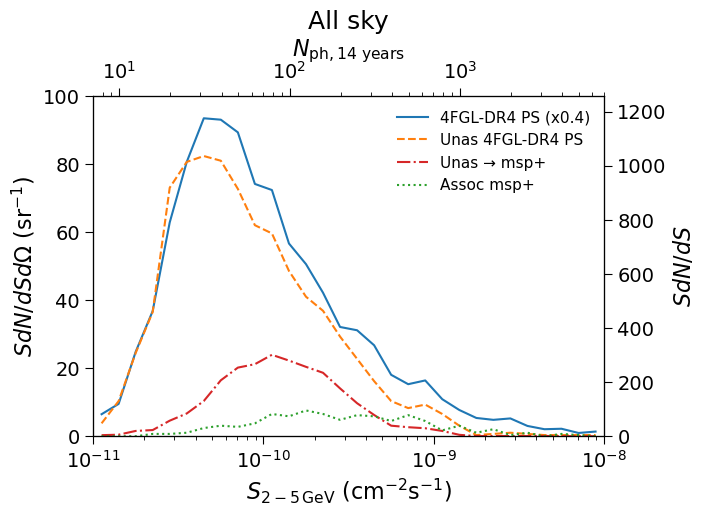

In [216]:
#msr = 5
#color = colors[lsi%len(colors)]
scaling = {'all_PS_allsky': 0.4} # {'all_PS_allsky': 0.3}, {}

pyplot.figure()
fig, ax1 = pyplot.subplots()

for key in ['all_PS_allsky', 'unas_PS_allsky', 'unas_cl_allsky', 'assoc_cl_allsky']:
    lsi = pinds[key]
    scale = scaling.get(key, 1.)
    label = plabels[key]
    if scale != 1:
        label += ' (x%.1f)' % scale
    pyplot.semilogx(Sc, SdNdS[key] * scale, ls=lss[lsi%len(lss)], c=colors[lsi%len(colors)], 
                    label=label)
    print(key, np.max(SdNdS[key]))


ymin = 0.
if len(scaling) == 0:
    ymax = 250.
else:
    ymax = 100.
ax1.set_ylim(ymin, ymax)
ax1.set_xlim(10**log10Smin, 10**log10Smax)
pyplot.legend(frameon=0)
ax1.set_xlabel(r'$S_{\rm %i - %i\, {\rm GeV}}\ (\rm cm^{-2} s^{-1})$' % (Emin, Emax))
ax1.set_ylabel(r'$S dN/dSd\Omega\ (\rm sr^{-1})$')

if show_title:
    pyplot.title('All sky')
else:
    pyplot.text(xtext, 0.65, 'All sky', #fontsize=14, 
                #fontfamily='monospace', 
                horizontalalignment='left', verticalalignment='top',
                transform=ax1.transAxes)



ax2 = ax1.twinx()
ax2.set_ylabel(r'$S dN/dS$')
ax2.set_ylim(ymin * Area_allsky_sr, ymax * Area_allsky_sr)
ax3 = ax1.twiny()
ax3.set_xlabel(r'$N_{\rm ph, %i\ years}$' % nyear)
xmin = 10**log10Smin * exposure(nyear)
xmax = 10**log10Smax * exposure(nyear)
ax3.set_xlim(xmin, xmax)
ax3.set_xscale('log')
if show_grid:
    ax1.grid()

#ax3.set_xlim(ymin * Area, ymax * Area)
if save_plots:
    fn = '%s/SdNdS_allsky_2GeV_%s.pdf' % (plots_folder, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    fn_png = fn.replace('.pdf', '.png')
    pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

In [217]:
FdNdF = {}

umaskF = unas_mask
weights = get_weights(cat_df, cl_inds, alg, umaskF)
Fdf = df_extra['Flux1000']
FdNdF['all_PS_allsky'] = Sc * np.histogram(Fdf, bins=Sb)[0] / dS / Area_allsky_sr
FdNdF['unas_PS_allsky'] = Sc * np.histogram(Fdf[umaskF], bins=Sb)[0] / dS / Area_allsky_sr
FdNdF['unas_cl_allsky'] = Sc * np.histogram(Fdf[umaskF], weights=weights, bins=Sb)[0]
FdNdF['unas_cl_allsky'] /=  dS * Area_allsky_sr
FdNdF['assoc_cl_allsky'] = Sc * np.histogram(Fdf[cl_mask], bins=Sb)[0] / dS / Area_allsky_sr



all_PS_allsky 228.62777444163015
unas_PS_allsky 80.69215568528269
unas_cl_allsky 26.871063613338507
assoc_cl_allsky 8.620956803983193
save figure to file: ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//SdNdS_allsky_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf


/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_94728/655806940.py:55: UserWarning: Unknown infodict keyword: 'Authors'. Must be one of {'Trapped', 'Keywords', 'Creator', 'Subject', 'CreationDate', 'ModDate', 'Title', 'Producer', 'Author'}.
  pyplot.savefig(fn, metadata=fig_meta)


cp ../..//plots/mclass/dNdS_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features//SdNdS_allsky_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf /Users/Dmitry/Work/Fermi/fermi_multiclass_papers/4_msp_multi_gce/msp_multi_gce_git_PRD/plots/main//SdNdS_allsky_4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_msp.pdf


<Figure size 700x500 with 0 Axes>

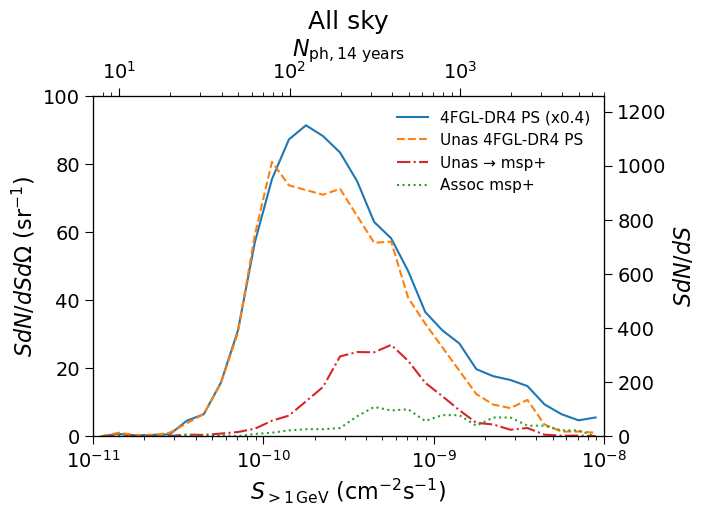

In [218]:
msr = 5
#lsi = 0
#color = colors[lsi%len(colors)]

pyplot.figure()
fig, ax1 = pyplot.subplots()

scaling = {'all_PS_allsky': 0.4} # {'all_PS_allsky': 0.3}, {}
for key in ['all_PS_allsky', 'unas_PS_allsky', 'unas_cl_allsky', 'assoc_cl_allsky']:
    lsi = pinds[key]
    scale = scaling.get(key, 1.)
    label = plabels[key]
    if scale != 1:
        label += ' (x%.1f)' % scale
    pyplot.semilogx(Sc, FdNdF[key] * scale, ls=lss[lsi%len(lss)], c=colors[lsi%len(colors)], 
                    label=label)
    print(key, np.max(FdNdF[key]))



ymin = 0.
if scaling is None:
    ymax = 250.
else:
    ymax = 100.
ax1.set_ylim(ymin, ymax)
ax1.set_xlim(10**log10Smin, 10**log10Smax)
pyplot.legend(loc='upper right', frameon=0)
ax1.set_xlabel(r'$S_{\rm > 1\, {\rm GeV}}\ (\rm cm^{-2} s^{-1})$')
ax1.set_ylabel(r'$S dN/dSd\Omega\ (\rm sr^{-1})$')

if show_title:
    pyplot.title('All sky')
else:
    pyplot.text(xtext, 0.65, 'All sky', #fontsize=14, 
                #fontfamily='monospace', 
                horizontalalignment='left', verticalalignment='top',
                transform=ax1.transAxes)

ax2 = ax1.twinx()
ax2.set_ylabel(r'$S dN/dS$')
ax2.set_ylim(ymin * Area_allsky_sr, ymax * Area_allsky_sr)
ax3 = ax1.twiny()
ax3.set_xlabel(r'$N_{\rm ph, %i\ years}$' % nyear)
xmin = 10**log10Smin * exposure(nyear)
xmax = 10**log10Smax * exposure(nyear)
ax3.set_xlim(xmin, xmax)
ax3.set_xscale('log')
if show_grid:
    ax1.grid()

if save_plots:
    fn = '%s/SdNdS_allsky_%s.pdf' % (plots_folder, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    fn_png = fn.replace('.pdf', '.png')
    pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

In [219]:
Acc = 2.5e4 # cm^2 sr
fsaa = 0.8
Aeff = fsaa * Acc / (4. * np.pi) # cm^2
T = 14 * 365 * 24 * 3600. # s
exp = Aeff * T
Eph = 2 * 1.6e-3 # 2 GeV in erg
W = Eph / exp
print(W)

4.554022836253958e-15


In [220]:
exp/1.e11

7.026754399484417

In [221]:
F = 1/exp
print(F)

1.423132136329362e-12


In [222]:
#df_extra[spat_mask]

(array([ 7., 16., 34., 41., 55., 45., 27., 22., 12., 14.,  4.,  0.,  4.,
         2.,  3.,  4.,  0.,  2.,  1.,  1.]),
 array([-9.722229  , -9.59603977, -9.46984959, -9.34366035, -9.21747017,
        -9.09128094, -8.96509171, -8.83890152, -8.71271229, -8.5865221 ,
        -8.46033287, -8.33414364, -8.20795345, -8.08176422, -7.95557451,
        -7.8293848 , -7.7031951 , -7.57700539, -7.45081615, -7.32462645,
        -7.19843674]),
 <BarContainer object of 20 artists>)

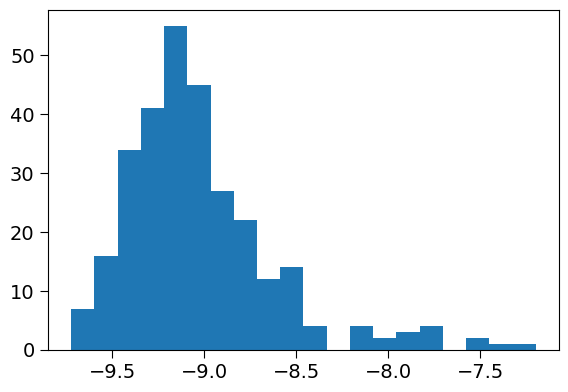

In [223]:
pyplot.hist(np.log10(df_extra[spat_mask]['Flux1000']), bins=20)

In [224]:
np.min(np.log10(df_extra[spat_mask]['Flux1000']))

-9.722229

In [225]:
nph_min = np.min(df_extra[spat_mask]['Flux1000']) * exp
print(nph_min)

133.20657222183388


In [226]:
np.min(np.log10(df_extra['Flux1000']))

-10.841623

In [227]:
nph_min = np.min(df_extra['Flux1000']) * exp
print(nph_min)

10.118853216567327


In [228]:
np.min(df_extra['Npred']), np.min(df_extra[spat_mask]['Npred'])

(11.915721, 145.99945)

In [229]:
W * np.median(df_extra[spat_mask]['Npred'])

3.4587503249413806e-12

In [230]:
df_extra.columns

Index(['Pivot_Energy', 'LP_Flux_Density', 'GLAT', 'GLON', 'Energy_Flux100',
       'Flags', 'Flux1000', 'Npred'],
      dtype='object')

(array([116.,  63.,  27.,  14.,  13.,   5.,   3.,   1.,   1.,   1.]),
 array([0.89056891, 1.25531018, 1.6200515 , 1.98479283, 2.34953403,
        2.71427536, 3.07901669, 3.44375801, 3.80849934, 4.17324066,
        4.53798199]),
 <BarContainer object of 10 artists>)

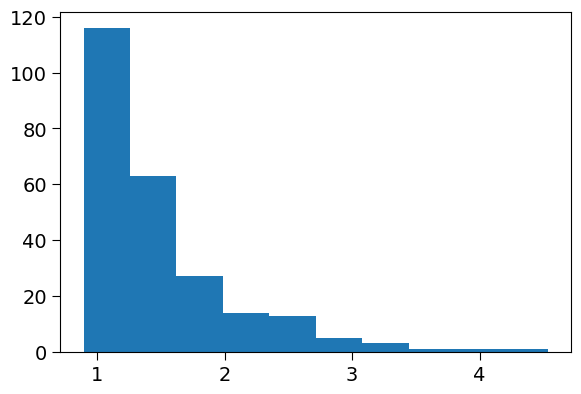

In [231]:
erg2GeV = 1000./1.6
pyplot.hist(df_extra['Energy_Flux100'][cl_mask]/df_extra['Flux1000'][cl_mask]*erg2GeV/np.sqrt(10.))